In [1]:

import json
import urllib.request

question = "What is the difference between a structural trap and a stratigraphic trap?"

data = {
    "model": "google/gemma-4-26B-A4B-it",
    "messages": [
        {
            "role": "system",
            "content": """You are an AI petroleum geoscientist.
Explain geological concepts, compare exploration
hypotheses, identify uncertainty, and recommend
next exploration steps. Never invent observations."""
        },
        {
            "role": "user",
            "content": question
        }
    ]
}

req = urllib.request.Request(
    "http://172.28.34.1:8000/v1/chat/completions",
    data=json.dumps(data).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(req, timeout=120) as response:
    result = json.load(response)

print(result["choices"][0]["message"]["content"])



In petroleum geoscience, a **trap** is a configuration of rocks that allows hydrocarbons to accumulate in a specific location by preventing them from migrating further upward or laterally. The distinction between structural and stratigraphic traps lies in the **mechanism** that creates the closure.

### 1. Structural Traps
A structural trap is formed by the **deformation of rock layers** due to tectonic forces (compression, tension, or shear). The geometry of the trap is created by the movement of the earth's crust.

*   **Mechanism:** Tectonic activity creates physical breaks or bends in the rock strata.
*   **Common Types:**
    *   **Anticline:** An upward-arching fold in the rock layers. This is the most classic trap type, where hydrocarbons migrate to the crest of the fold.
    *   **Fault Trap:** A fault line displaces a reservoir rock layer against an impermeable layer (like shale), sealing the reservoir.
    *   **Salt Dome (Diapir):** Upward movement of salt pierces through se

In [2]:

from pathlib import Path

# Location of the hackathon well data
folder = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data/las"
)

# Find all LAS files
wells = sorted(folder.glob("*.las"))

print("Number of wells found:", len(wells))

for well in wells:
    print(well.name)

# Open the first well and inspect available log curves
if wells:
    selected_well = wells[0]
    print("\nSELECTED WELL:", selected_well.name)
    print("\nAVAILABLE WELL LOG CURVES:")

    inside_curves = False

    with open(selected_well, errors="ignore") as file:
        for line in file:
            cleaned = line.strip()

            if cleaned.upper().startswith("~C"):
                inside_curves = True
                continue

            if inside_curves and cleaned.startswith("~"):
                break

            if inside_curves and cleaned and not cleaned.startswith("#"):
                print(cleaned)
else:
    print("No LAS files found. Check the data folder.")


Number of wells found: 13
eo-1.las
eo-2.las
m-1.las
no-1.las
no-2.las
no-4.las
np-1.las
np-2.las
o-1.las
o-2.las
o-3.las
p-1.las
s-1.las

SELECTED WELL: eo-1.las

AVAILABLE WELL LOG CURVES:
DEPTH.M                    :
VSH  .V/V                  :  Shale volume - VCLAY+VOL_CBW+VSILT
PHIT .V/V                  :  Limited total porosity
SWT  .V/V                  :  Total Sw - Limited
PS_GIP.MV                   :  Flag calculated by tp_paysummary
PS_OIP.MV                   :  Flag calculated by tp_paysummary


Well: eo-1
Valid VSH samples: 12121


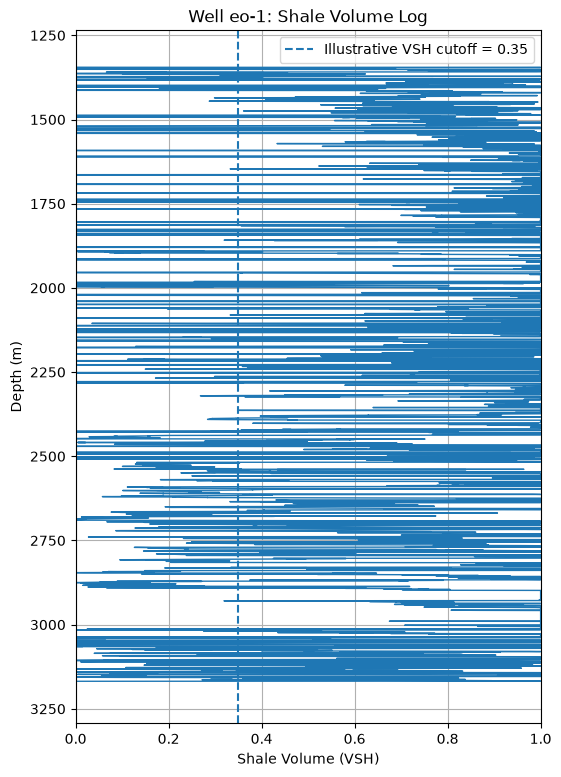

Relatively clean samples: 2764
Total valid samples: 12121


In [3]:

from pathlib import Path
import matplotlib.pyplot as plt

# Select the first well
file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data/las/eo-1.las"
)

depths = []
vsh_values = []
reading_data = False

# Read actual numerical well-log data
with open(file, errors="ignore") as f:
    for line in f:
        line = line.strip()

        if line.upper().startswith("~A"):
            reading_data = True
            continue

        if not reading_data:
            continue

        if line.startswith("~"):
            break

        if not line or line.startswith("#"):
            continue

        values = line.split()

        try:
            depth = float(values[0])
            vsh = float(values[1])

            # Exclude missing or invalid VSH values
            if 0 <= vsh <= 1:
                depths.append(depth)
                vsh_values.append(vsh)
        except (ValueError, IndexError):
            continue

print("Well: eo-1")
print("Valid VSH samples:", len(vsh_values))

if vsh_values:
    # Plot shale volume against depth
    plt.figure(figsize=(6, 9))

    plt.plot(vsh_values, depths, linewidth=1)

    # Illustrative clean/shaly cutoff
    plt.axvline(
        0.35,
        linestyle="--",
        label="Illustrative VSH cutoff = 0.35"
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Shale Volume (VSH)")
    plt.ylabel("Depth (m)")
    plt.title("Well eo-1: Shale Volume Log")
    plt.xlim(0, 1)
    plt.grid(True)
    plt.legend()
    plt.show()

    cleaner = sum(v < 0.35 for v in vsh_values)

    print("Relatively clean samples:", cleaner)
    print("Total valid samples:", len(vsh_values))
else:
    print("No valid data found. Check LAS format.")


In [4]:

from collections import defaultdict
import json
import urllib.request

# STEP 1: Group the actual well measurements
# into 50-metre intervals

intervals = defaultdict(list)

for depth, vsh in zip(depths, vsh_values):
    start = int(depth // 50) * 50
    intervals[start].append(vsh)

# STEP 2: Calculate geological summaries

results = []

for start, values in sorted(intervals.items()):

    if len(values) < 20:
        continue

    average_vsh = sum(values) / len(values)
    clean_fraction = sum(
        v < 0.35 for v in values
    ) / len(values)

    results.append({
        "depth_interval_m": f"{start}-{start+50}",
        "average_vsh": round(average_vsh, 3),
        "low_vsh_fraction": round(clean_fraction, 3),
        "sample_count": len(values)
    })

# Identify five relatively cleanest intervals
top_intervals = sorted(
    results,
    key=lambda x: x["average_vsh"]
)[:5]

print("TOP 5 RELATIVELY CLEAN INTERVALS")
print(json.dumps(top_intervals, indent=2))

# STEP 3: Send the evidence to your AI

prompt = f"""
You are an experienced petroleum geoscientist.

Analyse these REAL well-log summaries
from well eo-1:

{json.dumps(top_intervals, indent=2)}

Your tasks:

1. Explain which intervals appear relatively clean.
2. Explain whether sandstone is a plausible
   lithology, without claiming it is confirmed.
3. Discuss what the VSH measurements indicate.
4. Identify limitations of using VSH alone.
5. Recommend additional well logs and seismic
   attributes needed for interpretation.

Important:
- VSH < 0.35 is an illustrative cutoff.
- Low VSH does not prove sandstone.
- These are 50 m averages, not individual beds.
- Do not invent porosity, permeability or fluids.
- Do not claim hydrocarbon discovery.
- Clearly distinguish evidence from hypotheses.

Use headings and depth intervals in your answer.
"""

request_data = {
    "model": "google/gemma-4-26B-A4B-it",
    "messages": [
        {
            "role": "user",
            "content": prompt
        }
    ],
    "temperature": 0.2
}

req = urllib.request.Request(
    "http://172.28.34.1:8000/v1/chat/completions",
    data=json.dumps(request_data).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(req, timeout=120) as response:
    answer = json.load(response)

print("\nAI GEOLOGICAL INTERPRETATION\n")
print(answer["choices"][0]["message"]["content"])


TOP 5 RELATIVELY CLEAN INTERVALS
[
  {
    "depth_interval_m": "1300-1350",
    "average_vsh": 0.083,
    "low_vsh_fraction": 0.883,
    "sample_count": 137
  },
  {
    "depth_interval_m": "3150-3200",
    "average_vsh": 0.225,
    "low_vsh_fraction": 0.713,
    "sample_count": 328
  },
  {
    "depth_interval_m": "2650-2700",
    "average_vsh": 0.363,
    "low_vsh_fraction": 0.552,
    "sample_count": 306
  },
  {
    "depth_interval_m": "2500-2550",
    "average_vsh": 0.39,
    "low_vsh_fraction": 0.649,
    "sample_count": 328
  },
  {
    "depth_interval_m": "2600-2650",
    "average_vsh": 0.474,
    "low_vsh_fraction": 0.441,
    "sample_count": 288
  }
]

AI GEOLOGICAL INTERPRETATION

As an experienced petroleum geoscientist, I have reviewed the provided Vshale ($V_{sh}$) summary data for well EO-1. Below is my technical analysis based strictly on the provided parameters.

### 1. Analysis of Cleanliness by Interval
Using the illustrative cutoff of $V_{sh} < 0.35$ to define "rela

Valid combined samples: 10858


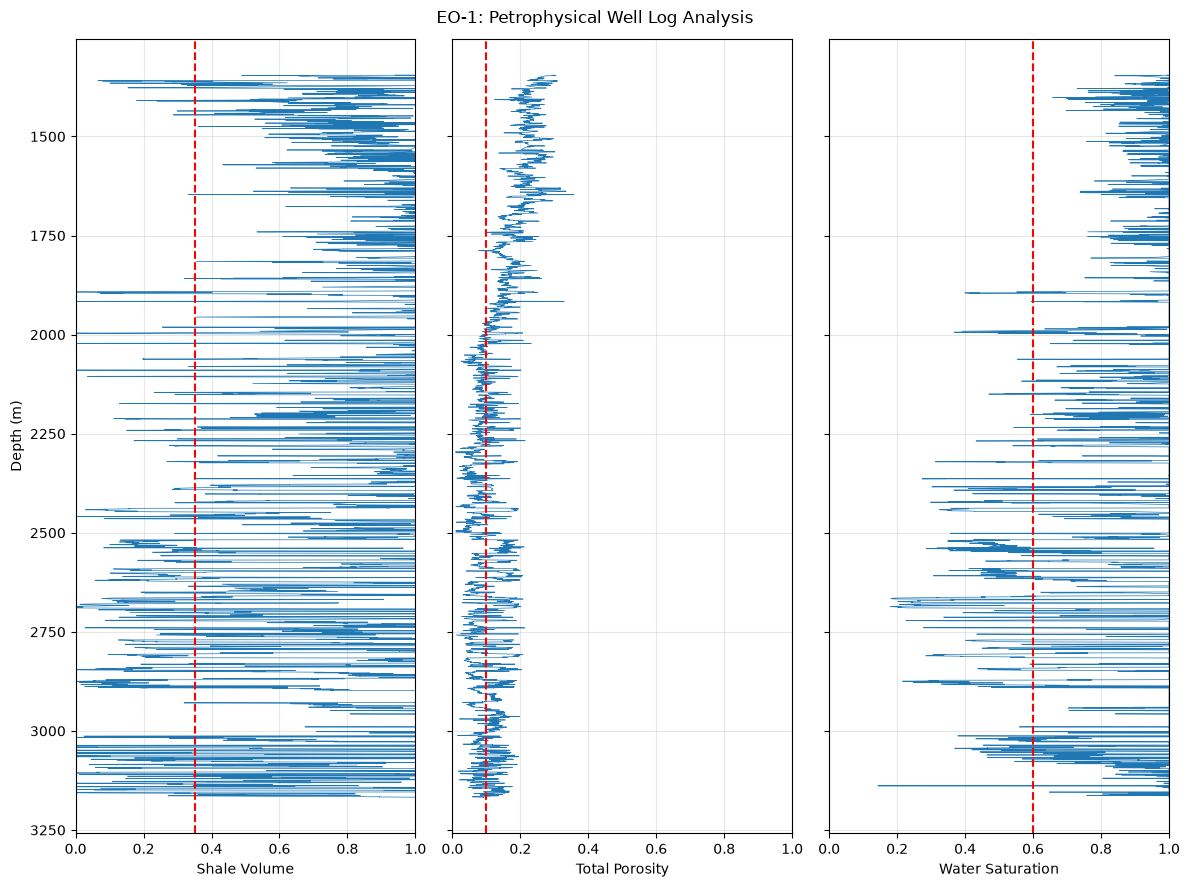


TOP 5 SCREENING INTERVALS

{'interval': '2500-2550 m', 'samples': 286, 'mean_vsh': 0.429, 'mean_phit': 0.141, 'mean_swt': 0.597, 'screening_fraction': 0.573}
{'interval': '2650-2700 m', 'samples': 306, 'mean_vsh': 0.363, 'mean_phit': 0.124, 'mean_swt': 0.56, 'screening_fraction': 0.48}
{'interval': '2800-2850 m', 'samples': 328, 'mean_vsh': 0.572, 'mean_phit': 0.109, 'mean_swt': 0.78, 'screening_fraction': 0.308}
{'interval': '2850-2900 m', 'samples': 328, 'mean_vsh': 0.537, 'mean_phit': 0.097, 'mean_swt': 0.794, 'screening_fraction': 0.284}
{'interval': '2600-2650 m', 'samples': 288, 'mean_vsh': 0.474, 'mean_phit': 0.116, 'mean_swt': 0.781, 'screening_fraction': 0.25}

Screening fraction = proportion of samples meeting all three illustrative thresholds.


In [5]:

from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

well_path = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data/las/eo-1.las"
)

records = []
reading = False

with open(well_path, errors="ignore") as f:
    for line in f:
        line = line.strip()

        if line.upper().startswith("~A"):
            reading = True
            continue

        if not reading or not line or line.startswith("#"):
            continue

        if line.startswith("~"):
            break

        try:
            v = [float(x) for x in line.split()]

            # Verified from your LAS curve header:
            # DEPTH, VSH, PHIT, SWT
            depth, vsh, phit, swt = v[:4]

            if (0 <= vsh <= 1 and
                0 <= phit <= 1 and
                0 <= swt <= 1):
                records.append((depth, vsh, phit, swt))

        except (ValueError, IndexError):
            continue

print("Valid combined samples:", len(records))

if not records:
    print("No complete records found. Check the LAS data.")

else:
    # Plot the three actual well measurements
    records.sort(key=lambda x: x[0])

    depth = [r[0] for r in records]
    vsh = [r[1] for r in records]
    phit = [r[2] for r in records]
    swt = [r[3] for r in records]

    fig, axes = plt.subplots(
        1, 3, figsize=(12, 9), sharey=True
    )

    for ax, values, name, limit in zip(
        axes,
        [vsh, phit, swt],
        ["Shale Volume", "Total Porosity",
         "Water Saturation"],
        [0.35, 0.10, 0.60]
    ):
        ax.plot(values, depth, linewidth=0.5)
        ax.axvline(limit, color="red", linestyle="--")
        ax.set_xlim(0, 1)
        ax.set_xlabel(name)
        ax.grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel("Depth (m)")
    fig.suptitle("EO-1: Petrophysical Well Log Analysis")
    plt.tight_layout()
    plt.show()

    # Summarise 50 m intervals
    groups = defaultdict(list)

    for d, v, p, s in records:
        start = int(d // 50) * 50
        groups[start].append((v, p, s))

    screening_results = []

    for start, samples in sorted(groups.items()):
        if len(samples) < 20:
            continue

        n = len(samples)

        qualifying = sum(
            v < 0.35 and p >= 0.10 and s < 0.60
            for v, p, s in samples
        )

        screening_results.append({
            "interval": f"{start}-{start+50} m",
            "samples": n,
            "mean_vsh": round(
                sum(x[0] for x in samples) / n, 3
            ),
            "mean_phit": round(
                sum(x[1] for x in samples) / n, 3
            ),
            "mean_swt": round(
                sum(x[2] for x in samples) / n, 3
            ),
            "screening_fraction": round(
                qualifying / n, 3
            )
        })

    screening_results.sort(
        key=lambda x: x["screening_fraction"],
        reverse=True
    )

    print("\nTOP 5 SCREENING INTERVALS\n")

    for item in screening_results[:5]:
        print(item)

    print(
        "\nScreening fraction = proportion of samples "
        "meeting all three illustrative thresholds."
    )


In [6]:

import json
import urllib.request

# Use the actual results from your previous cell
evidence = screening_results[:5]

question = """
Based on the EO-1 petrophysical data:

1. Which intervals deserve further reservoir evaluation?
2. Explain the significance of VSH, PHIT and SWT.
3. Which intervals might be relatively sand-prone?
4. What are the main geological uncertainties?
5. What additional evidence is needed before
   identifying a potential hydrocarbon reservoir?

Rank the intervals by their preliminary
petrophysical screening results.
"""

system_prompt = """
You are Exploration Copilot, an expert petroleum
geoscience assistant.

Analyse the supplied real well-log summaries.

IMPORTANT RULES:
- Only use the evidence supplied.
- VSH is estimated shale volume.
- PHIT is total porosity, not effective porosity.
- SWT is total water saturation.
- Screening criteria are illustrative:
  VSH < 0.35, PHIT >= 0.10, SWT < 0.60.
- Screening fraction measures the proportion
  of valid samples meeting all three criteria.
- An interval's average values may differ
  from the values of qualifying samples.
- Do not identify confirmed sandstone or oil/gas.
- Do not claim that a reservoir or trap is proven.
- Explain supporting evidence and uncertainties.
- Recommend specific further geological analysis.

Provide a professional, evidence-based explanation.
"""

user_prompt = f"""
WELL: EO-1

ACTUAL PETROPHYSICAL SUMMARY:
{json.dumps(evidence, indent=2)}

GEOSCIENTIST QUESTION:
{question}
"""

payload = {
    "model": "google/gemma-4-26B-A4B-it",
    "messages": [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ],
    "temperature": 0.2
}

req = urllib.request.Request(
    "http://172.28.34.1:8000/v1/chat/completions",
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(req, timeout=120) as response:
    result = json.load(response)

print("=" * 55)
print("EXPLORATION COPILOT — EO-1 WELL INTERPRETATION")
print("=" * 55)

print(result["choices"][0]["message"]["content"])


EXPLORATION COPILOT — EO-1 WELL INTERPRETATION
### Petrophysical Analysis Report: Well EO-1

This report provides an evaluation of the petrophysical data supplied for well EO-1. The analysis is based on the provided screening criteria: **VSH < 0.35**, **PHIT $\ge$ 0.10**, and **SWT < 0.60**.

---

#### 1. Interval Ranking (Preliminary Screening)
The intervals are ranked below based on their **Screening Fraction** (the proportion of samples meeting all three quality criteria). A higher fraction indicates a higher density of samples that simultaneously satisfy the low shale, high porosity, and low water saturation thresholds.

| Rank | Interval (m) | Screening Fraction | Mean VSH | Mean PHIT | Mean SWT |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | 2500–2550 | **0.573** | 0.429 | 0.141 | 0.597 |
| **2** | 2650–2700 | **0.480** | 0.363 | 0.124 | 0.560 |
| **3** | 2800–2850 | **0.308** | 0.572 | 0.109 | 0.780 |
| **4** | 2850–2900 | **0.284** | 0.537 | 0.097 | 0.794 |
| **5** | 26

In [7]:

from pathlib import Path
import importlib.util

folder = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2"
)

seismic_files = sorted(folder.rglob("*.sgy"))

print("SEISMIC FILES FOUND:", len(seismic_files))

for file in seismic_files:
    print(file.name)

print("\nSegyio installed:",
      importlib.util.find_spec("segyio") is not None)


SEISMIC FILES FOUND: 9
Challenge1_Challenge2_Inversion_P_Impedance_cropped.sgy
Challenge1_Challenge2_Inversion_S_Impedance_cropped.sgy
Challenge1_Challenge2_Inversion_TotalSandProbability_cropped.sgy
Challenge1_Challenge2_Inversion_VpVs_cropped.sgy
Challenge1_Challenge2_Far_Stack_cropped.sgy
Challenge1_Challenge2_Full_Stack_cropped.sgy
Challenge1_Challenge2_Mid_Stack_cropped.sgy
Challenge1_Challenge2_Near_Stack_cropped.sgy
Challenge1_Challenge2_UltraFar_Stack_cropped.sgy

Segyio installed: True


In [8]:

import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Select the real full-stack seismic volume
seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

if not seismic_file.exists():
    print("ERROR: Seismic file not found.")

else:
    with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:
        # Select the middle inline
        inline_number = int(
            f.ilines[len(f.ilines) // 2]
        )

        # Read only one inline, not the full cube
        section = np.asarray(
            f.iline[inline_number]
        )

        samples = np.asarray(f.samples)

        print("Selected Inline:", inline_number)
        print("Section shape:", section.shape)
        print("Number of samples:", len(samples))
        print("Sample-axis range:",
              samples[0], "to", samples[-1])

    # Handle possible offset dimension
    if section.ndim == 3:
        section = section[:, 0, :]

    # Set amplitude display scale
    clip = np.nanpercentile(
        np.abs(section), 99
    )

    if not np.isfinite(clip) or clip == 0:
        clip = 1.0

    # Display the seismic section
    plt.figure(figsize=(13, 7))

    plt.imshow(
        section.T,
        cmap="gray",
        aspect="auto",
        origin="upper",
        vmin=-clip,
        vmax=clip
    )

    plt.title(
        f"Full-Stack Seismic - Inline {inline_number}"
    )

    plt.xlabel("Crossline index")
    plt.ylabel("Seismic sample index (not depth)")
    plt.colorbar(label="Seismic amplitude")
    plt.tight_layout()
    plt.show()


ValueError: Inlines inconsistent, expect all inlines to be unique

SUCCESS! Seismic file opened.
Total traces: 1453018
Samples per trace: 876
Sample axis: 0.0 to 3500.0

TRACE HEADER CHECK
Trace: 726409 | Inline: 1988 | Crossline: 3885
Trace: 726509 | Inline: 1988 | Crossline: 4085
Trace: 726608 | Inline: 1988 | Crossline: 4283


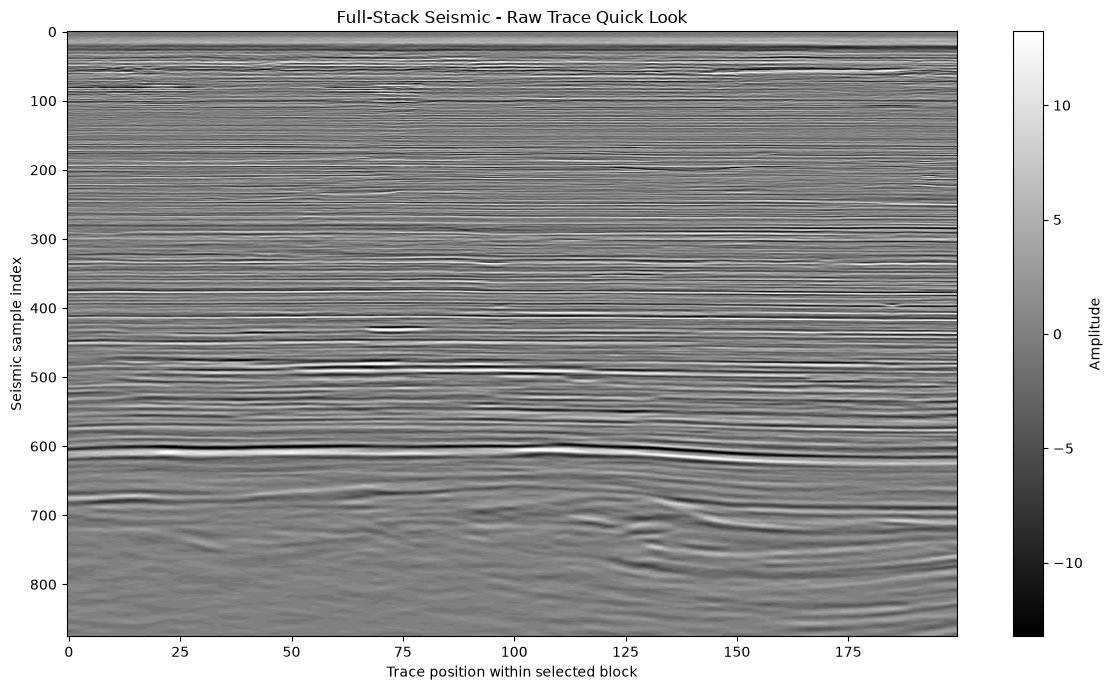


Raw seismic trace visualisation completed!


In [9]:

import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

# Open seismic without automatic geometry detection
with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:

    total_traces = f.tracecount
    samples = np.asarray(f.samples)

    print("SUCCESS! Seismic file opened.")
    print("Total traces:", total_traces)
    print("Samples per trace:", len(samples))
    print("Sample axis:", samples[0], "to", samples[-1])

    # Read 200 consecutive traces near the middle
    start = max(0, total_traces // 2 - 100)
    end = min(total_traces, start + 200)

    section = np.stack([
        np.copy(f.trace[i])
        for i in range(start, end)
    ])

    # Inspect actual seismic geometry headers
    print("\nTRACE HEADER CHECK")

    for i in [start, (start + end) // 2, end - 1]:
        header = f.header[i]

        inline = header[segyio.TraceField.INLINE_3D]
        crossline = header[segyio.TraceField.CROSSLINE_3D]

        print(
            "Trace:", i,
            "| Inline:", inline,
            "| Crossline:", crossline
        )

# Display raw seismic traces
clip = np.nanpercentile(np.abs(section), 99)

if not np.isfinite(clip) or clip == 0:
    clip = 1.0

plt.figure(figsize=(12, 7))

plt.imshow(
    section.T,
    cmap="gray",
    aspect="auto",
    origin="upper",
    vmin=-clip,
    vmax=clip
)

plt.title("Full-Stack Seismic - Raw Trace Quick Look")
plt.xlabel("Trace position within selected block")
plt.ylabel("Seismic sample index")
plt.colorbar(label="Amplitude")
plt.tight_layout()
plt.show()

print("\nRaw seismic trace visualisation completed!")


Selected inline: 1988
Traces found: 1778
Crossline range: 1427 to 4981
Section shape: (1778, 876)


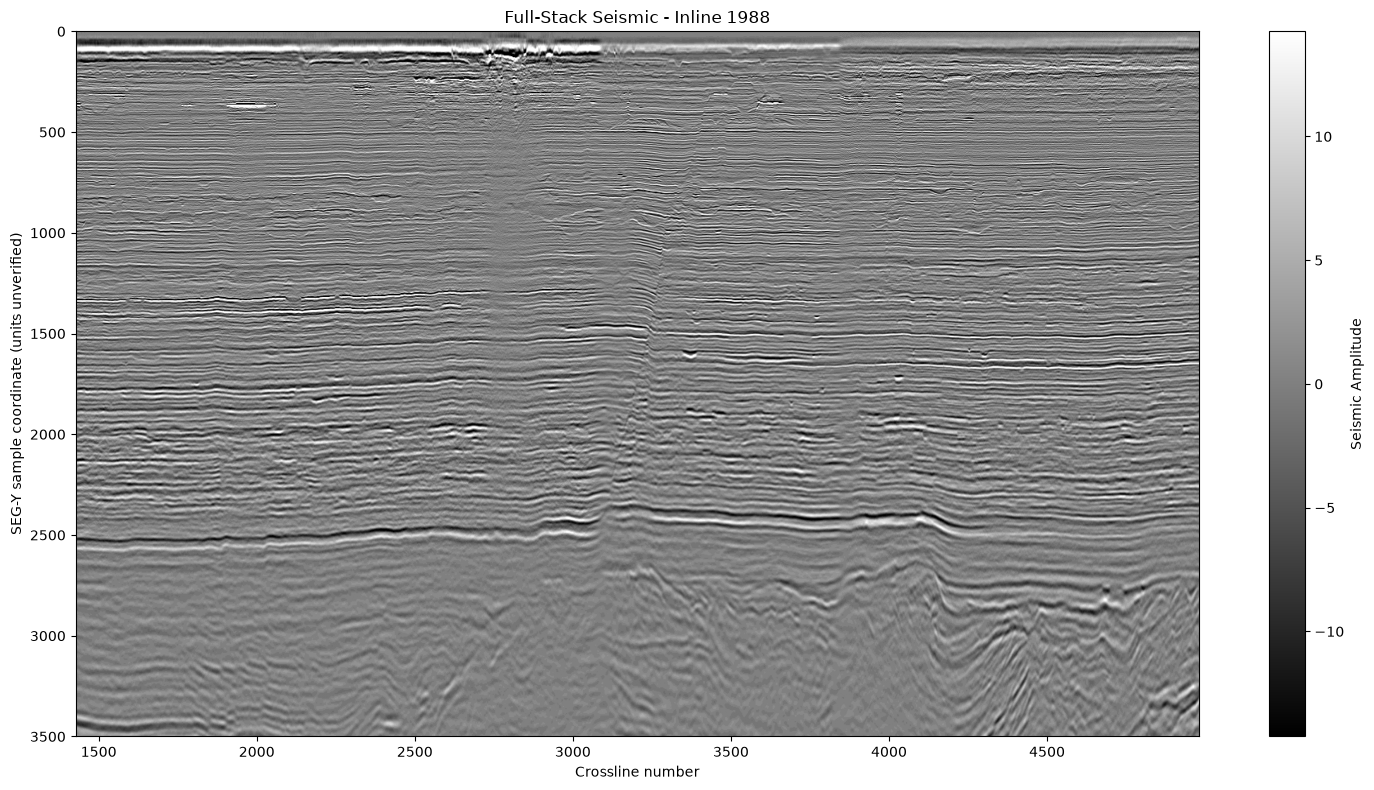

COMPLETE INLINE VISUALISATION FINISHED!


In [10]:

import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

target_inline = 1988

with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:

    # Read inline and crossline numbers from headers
    all_inlines = f.attributes(
        segyio.TraceField.INLINE_3D
    )[:]

    all_crosslines = f.attributes(
        segyio.TraceField.CROSSLINE_3D
    )[:]

    # Locate every trace belonging to Inline 1988
    trace_indices = np.where(
        all_inlines == target_inline
    )[0]

    print("Selected inline:", target_inline)
    print("Traces found:", len(trace_indices))

    if len(trace_indices) == 0:
        raise ValueError("Inline not found!")

    # Arrange traces by crossline number
    order = np.argsort(
        all_crosslines[trace_indices]
    )

    trace_indices = trace_indices[order]
    sorted_crosslines = all_crosslines[trace_indices]

    # Keep one trace per crossline for this quick look
    crosslines, first_positions = np.unique(
        sorted_crosslines,
        return_index=True
    )

    if len(crosslines) < len(trace_indices):
        print(
            "WARNING: Repeated crosslines found.",
            "Showing the first trace at each crossline."
        )

    trace_indices = trace_indices[first_positions]

    # Read the selected inline
    section = np.stack([
        np.copy(f.trace[int(i)])
        for i in trace_indices
    ])

    samples = np.asarray(f.samples)

    print("Crossline range:",
          crosslines[0], "to", crosslines[-1])

    print("Section shape:", section.shape)

    # Inspect crossline spacing
    spacing = np.diff(crosslines)
    regular = (
        len(spacing) > 0 and
        np.all(spacing == spacing[0])
    )

# Display the complete inline
clip = np.nanpercentile(np.abs(section), 99)

if not np.isfinite(clip) or clip == 0:
    clip = 1.0

plt.figure(figsize=(15, 8))

if regular:
    extent = [
        crosslines[0],
        crosslines[-1],
        samples[-1],
        samples[0]
    ]
    xlabel = "Crossline number"
else:
    extent = [
        0,
        len(crosslines) - 1,
        samples[-1],
        samples[0]
    ]
    xlabel = "Trace index (sorted by crossline)"
    print("Irregular crossline spacing detected.")

plt.imshow(
    section.T,
    cmap="gray",
    aspect="auto",
    origin="upper",
    extent=extent,
    vmin=-clip,
    vmax=clip
)

plt.title(
    f"Full-Stack Seismic - Inline {target_inline}"
)

plt.xlabel(xlabel)
plt.ylabel("SEG-Y sample coordinate (units unverified)")
plt.colorbar(label="Seismic Amplitude")
plt.tight_layout()
plt.show()

print("COMPLETE INLINE VISUALISATION FINISHED!")


In [11]:

import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2"
)

files = {
    "Full Stack": base / "stack" /
        "Challenge1_Challenge2_Full_Stack_cropped.sgy",

    "Sand Probability": base / "inversion" /
        "Challenge1_Challenge2_Inversion_TotalSandProbability_cropped.sgy"
}

target_inline = 1988

def read_inline(path, inline_number):

    with segyio.open(
        str(path), "r", ignore_geometry=True
    ) as f:

        il = f.attributes(
            segyio.TraceField.INLINE_3D
        )[:]

        indices = np.where(il == inline_number)[0]

        if len(indices) == 0:
            raise ValueError(
                f"Inline {inline_number} not found in {path.name}"
            )

        xl = f.attributes(
            segyio.TraceField.CROSSLINE_3D
        )[indices]

        # Sort by crossline
        order = np.argsort(xl, kind="stable")
        indices = indices[order]
        xl = xl[order]

        # Detect duplicate locations
        unique_xl, first = np.unique(
            xl, return_index=True
        )

        if len(unique_xl) != len(xl):
            print(
                "WARNING: Duplicate crosslines in",
                path.name,
                "- displaying first trace only."
            )

        indices = indices[first]

        traces = np.stack([
            np.copy(f.trace[int(i)])
            for i in indices
        ])

        samples = np.asarray(f.samples).copy()

    return unique_xl, samples, traces


# Read both real seismic volumes
x1, t1, full = read_inline(
    files["Full Stack"], target_inline
)

x2, t2, sand = read_inline(
    files["Sand Probability"], target_inline
)

# Check whether the sample axes match
if not np.array_equal(t1, t2):
    raise ValueError(
        "Sample axes differ between volumes. "
        "Time/depth alignment is required."
    )

# Match traces using the actual crossline numbers
common = np.intersect1d(x1, x2)

if len(common) == 0:
    raise ValueError("No matching crosslines found.")

idx1 = np.searchsorted(x1, common)
idx2 = np.searchsorted(x2, common)

full = full[idx1]
sand = sand[idx2]

print("MATCHED INLINE:", target_inline)
print("Common crosslines:", len(common))
print("Crossline range:", common[0], common[-1])
print("Sample range:", t1[0], t1[-1])
print("Sand attribute range:",
      np.nanmin(sand), np.nanmax(sand))

# Display scale for seismic
clip = np.nanpercentile(np.abs(full), 99)

if not np.isfinite(clip) or clip <= 0:
    clip = 1

# Check the sand probability scale
sand_min = np.nanmin(sand)
sand_max = np.nanmax(sand)

if sand_min >= 0 and sand_max <= 1:
    sand_display = sand
    sand_label = "Sand Probability (0-1)"

elif sand_min >= 0 and sand_max <= 100:
    sand_display = sand / 100
    sand_label = "Sand Probability (0-1, scaled)"

else:
    sand_display = sand
    sand_label = "Sand Attribute (scale unverified)"
    print("WARNING: Verify sand attribute units.")

# Plot matching traces side by side
fig, axes = plt.subplots(
    1, 2, figsize=(15, 8), sharey=True
)

extent = [
    -0.5, len(common) - 0.5,
    t1[-1], t1[0]
]

axes[0].imshow(
    full.T,
    cmap="gray",
    aspect="auto",
    extent=extent,
    vmin=-clip,
    vmax=clip
)

axes[0].set_title(
    f"Full-Stack Seismic - Inline {target_inline}"
)

im = axes[1].imshow(
    sand_display.T,
    cmap="viridis",
    aspect="auto",
    extent=extent
)

axes[1].set_title(
    "Total Sand Probability Inversion"
)

ticks = np.linspace(
    0, len(common) - 1,
    min(6, len(common)),
    dtype=int
)

for ax in axes:
    ax.set_xticks(ticks)
    ax.set_xticklabels(common[ticks])
    ax.set_xlabel("Crossline number")
    ax.grid(False)

axes[0].set_ylabel(
    "SEG-Y sample coordinate (units unverified)"
)

fig.colorbar(
    im, ax=axes[1],
    label=sand_label,
    shrink=0.75
)

plt.tight_layout()
plt.show()

print("SEISMIC COMPARISON COMPLETED!")


ValueError: Sample axes differ between volumes. Time/depth alignment is required.

In [12]:

import numpy as np

print("FULL-STACK SEISMIC")
print("Number of samples:", len(t1))
print("First sample:", t1[0])
print("Last sample:", t1[-1])
print("First 5 samples:", t1[:5])
print("Average sample spacing:", np.mean(np.diff(t1)))

print("\nSAND PROBABILITY INVERSION")
print("Number of samples:", len(t2))
print("First sample:", t2[0])
print("Last sample:", t2[-1])
print("First 5 samples:", t2[:5])
print("Average sample spacing:", np.mean(np.diff(t2)))

print("\nCOMPARISON")
print("Same number of samples:", len(t1) == len(t2))

if len(t1) == len(t2):
    print("Maximum coordinate difference:",
          np.max(np.abs(t1 - t2)))
    print("Approximately equal:",
          np.allclose(t1, t2, rtol=0, atol=1e-3))

print("\nCommon coordinate range:")
print("Start:", max(t1.min(), t2.min()))
print("End:", min(t1.max(), t2.max()))


FULL-STACK SEISMIC
Number of samples: 876
First sample: 0.0
Last sample: 3500.0
First 5 samples: [ 0.  4.  8. 12. 16.]
Average sample spacing: 4.0

SAND PROBABILITY INVERSION
Number of samples: 751
First sample: 0.0
Last sample: 3000.0
First 5 samples: [ 0.  4.  8. 12. 16.]
Average sample spacing: 4.0

COMPARISON
Same number of samples: False

Common coordinate range:
Start: 0.0
End: 3000.0


SEISMIC ALIGNMENT SUCCESSFUL!
Inline: 1988
Matching crosslines: 1778
Full stack shape: (1778, 751)
Sand probability shape: (1778, 751)
Vertical range: 0.0 to 3000.0
Sand attribute range: 0.0 to 0.99998224


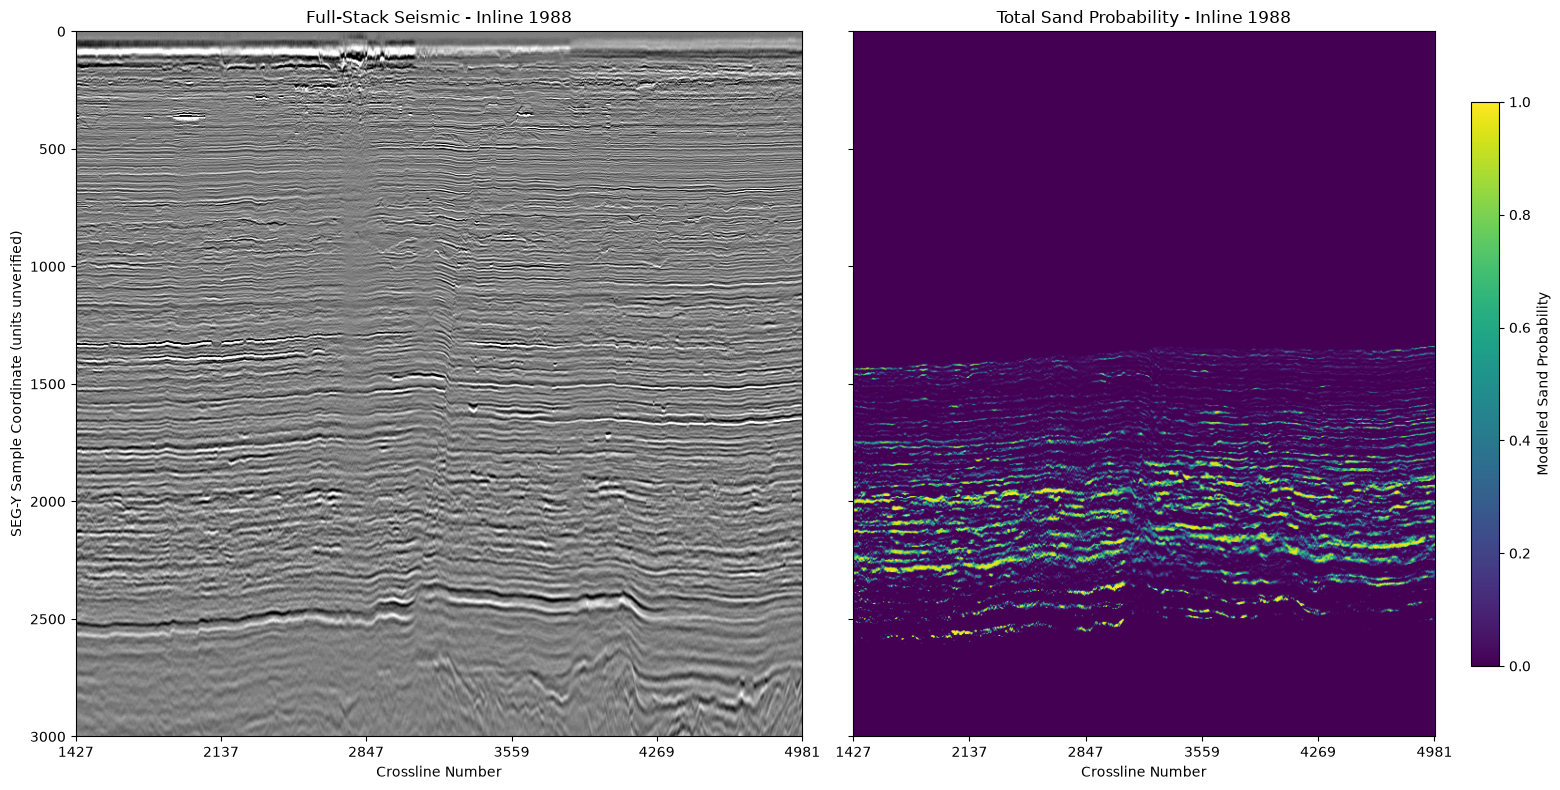


COMPARISON COMPLETED SUCCESSFULLY!


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# STEP 1: Check vertical sample alignment
# Full stack: 876 samples
# Sand probability: 751 samples

if not np.allclose(
    t1[:len(t2)], t2,
    rtol=0, atol=1e-5
):
    raise ValueError(
        "Sample coordinates do not match."
    )

# STEP 2: Match seismic crosslines
common = np.intersect1d(x1, x2)

if len(common) == 0:
    raise ValueError("No matching crosslines!")

i1 = np.searchsorted(x1, common)
i2 = np.searchsorted(x2, common)

# STEP 3: Crop full stack to match inversion
full_aligned = full[i1, :len(t2)]
sand_aligned = sand[i2, :]

print("SEISMIC ALIGNMENT SUCCESSFUL!")
print("Inline:", target_inline)
print("Matching crosslines:", len(common))
print("Full stack shape:", full_aligned.shape)
print("Sand probability shape:", sand_aligned.shape)
print("Vertical range:", t2[0], "to", t2[-1])

# STEP 4: Prepare display scales
clip = np.nanpercentile(
    np.abs(full_aligned), 99
)

if not np.isfinite(clip) or clip == 0:
    clip = 1.0

sand_min = np.nanmin(sand_aligned)
sand_max = np.nanmax(sand_aligned)

print("Sand attribute range:",
      sand_min, "to", sand_max)

if 0 <= sand_min and sand_max <= 1:
    sand_plot = sand_aligned
    sand_label = "Modelled Sand Probability"
    vmin, vmax = 0, 1

elif 0 <= sand_min and sand_max <= 100:
    sand_plot = sand_aligned / 100
    sand_label = "Modelled Sand Probability"
    vmin, vmax = 0, 1

else:
    sand_plot = sand_aligned
    sand_label = "Sand Attribute (scale unverified)"
    vmin, vmax = None, None
    print("WARNING: Verify attribute scaling.")

# STEP 5: Plot two matching sections
fig, axes = plt.subplots(
    1, 2, figsize=(16, 8), sharey=True
)

extent = [
    -0.5,
    len(common) - 0.5,
    t2[-1],
    t2[0]
]

axes[0].imshow(
    full_aligned.T,
    cmap="gray",
    aspect="auto",
    extent=extent,
    vmin=-clip,
    vmax=clip
)

axes[0].set_title(
    "Full-Stack Seismic - Inline 1988"
)

im = axes[1].imshow(
    sand_plot.T,
    cmap="viridis",
    aspect="auto",
    extent=extent,
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(
    "Total Sand Probability - Inline 1988"
)

# Display actual crossline labels
ticks = np.linspace(
    0, len(common)-1,
    min(6, len(common)),
    dtype=int
)

for ax in axes:
    ax.set_xticks(ticks)
    ax.set_xticklabels(common[ticks])
    ax.set_xlabel("Crossline Number")

axes[0].set_ylabel(
    "SEG-Y Sample Coordinate (units unverified)"
)

fig.colorbar(
    im,
    ax=axes[1],
    label=sand_label,
    shrink=0.8
)

plt.tight_layout()
plt.show()

print("\nCOMPARISON COMPLETED SUCCESSFULLY!")


In [14]:

import numpy as np
import json
import urllib.request

# Use the aligned seismic data from Step 10
# full_aligned = seismic amplitude
# sand_aligned = modelled sand probability
# common = matching crosslines
# t2 = common vertical sample coordinates

# Divide the seismic section into analysis windows
vertical_bins = np.arange(1400, 2801, 200)
crossline_groups = np.array_split(
    np.arange(len(common)), 4
)

seismic_evidence = []

for group_no, cross_indices in enumerate(
    crossline_groups, start=1
):
    for start, end in zip(
        vertical_bins[:-1],
        vertical_bins[1:]
    ):

        sample_mask = (t2 >= start) & (t2 < end)

        probability = sand_aligned[
            cross_indices
        ][:, sample_mask]

        amplitude = full_aligned[
            cross_indices
        ][:, sample_mask]

        valid_p = probability[np.isfinite(probability)]
        valid_a = amplitude[np.isfinite(amplitude)]

        if len(valid_p) == 0:
            continue

        result = {
            "crossline_start": int(
                common[cross_indices[0]]
            ),
            "crossline_end": int(
                common[cross_indices[-1]]
            ),
            "sample_interval": f"{start}-{end}",
            "mean_sand_probability": round(
                float(np.mean(valid_p)), 3
            ),
            "high_probability_fraction": round(
                float(np.mean(valid_p >= 0.6)), 3
            ),
            "zero_fraction": round(
                float(np.mean(valid_p == 0)), 3
            ),
            "seismic_rms_amplitude": round(
                float(np.sqrt(np.mean(valid_a**2))), 3
            ) if len(valid_a) else None
        }

        seismic_evidence.append(result)

# Rank regions by their proportion of high values
seismic_evidence.sort(
    key=lambda x: x["high_probability_fraction"],
    reverse=True
)

top_regions = seismic_evidence[:5]

print("TOP 5 SAND-PRONE SEISMIC WINDOWS")
print(json.dumps(top_regions, indent=2))

# Check whether exact zeros may need QC
zero_fraction_all = np.mean(
    sand_aligned[np.isfinite(sand_aligned)] == 0
)

print(
    "\nFraction of exact zero values in section:",
    round(float(zero_fraction_all), 3)
)

print(
    "\nIMPORTANT: Exact zeros may be valid values "
    "or masked/no-data cells. Verify before "
    "quantitative geological interpretation."
)

# Send real seismic evidence to Gemma
prompt = f"""
You are Exploration Copilot, an experienced
petroleum geoscience assistant.

Interpret the following numerical evidence
from REAL seismic inversion data.

INLINE: 1988

DATA:
{json.dumps(top_regions, indent=2)}

Definitions:
- Mean sand probability is the average
  modelled probability within a window.
- High probability fraction represents
  samples with modelled probability >= 0.6.
- RMS amplitude measures seismic amplitude
  strength, not reservoir quality directly.
- Exact zero probability values may
  represent low probability or no-data.
- Vertical coordinate units are unverified.
- These windows have NOT been tied to wells.

Answer these questions:

1. Which seismic windows have the strongest
   modelled sand-prone evidence?

2. Explain how sand probability and seismic
   amplitude contribute different information.

3. What geological hypotheses could explain
   the observed distribution?

4. Can we identify a structural or
   stratigraphic trap from these measurements?

5. What additional seismic interpretation
   is required?

RULES:
- Do not invent faults, pinch-outs or closure.
- Do not claim hydrocarbons were discovered.
- Distinguish observations from hypotheses.
- Do not equate seismic coordinates with
  well depth.
- Explain uncertainty and data limitations.
"""

payload = {
    "model": "google/gemma-4-26B-A4B-it",
    "messages": [
        {
            "role": "system",
            "content": (
                "You are an evidence-based AI "
                "exploration geoscientist."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    "temperature": 0.2
}

req = urllib.request.Request(
    "http://172.28.34.1:8000/v1/chat/completions",
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(
    req, timeout=120
) as response:
    ai_result = json.load(response)

print("\n" + "=" * 55)
print("EXPLORATION COPILOT - SEISMIC INTERPRETATION")
print("=" * 55)

print(
    ai_result["choices"][0]["message"]["content"]
)


TOP 5 SAND-PRONE SEISMIC WINDOWS
[
  {
    "crossline_start": 3207,
    "crossline_end": 4093,
    "sample_interval": "2000-2200",
    "mean_sand_probability": 0.229,
    "high_probability_fraction": 0.163,
    "zero_fraction": 0.043,
    "seismic_rms_amplitude": 3.958
  },
  {
    "crossline_start": 3207,
    "crossline_end": 4093,
    "sample_interval": "1800-2000",
    "mean_sand_probability": 0.195,
    "high_probability_fraction": 0.141,
    "zero_fraction": 0.064,
    "seismic_rms_amplitude": 4.34
  },
  {
    "crossline_start": 1427,
    "crossline_end": 2315,
    "sample_interval": "2200-2400",
    "mean_sand_probability": 0.178,
    "high_probability_fraction": 0.137,
    "zero_fraction": 0.14,
    "seismic_rms_amplitude": 4.112
  },
  {
    "crossline_start": 4095,
    "crossline_end": 4981,
    "sample_interval": "2000-2200",
    "mean_sand_probability": 0.202,
    "high_probability_fraction": 0.136,
    "zero_fraction": 0.033,
    "seismic_rms_amplitude": 3.581
  },
  {
   

SAND PROBABILITY QUALITY CONTROL
Total samples: 1335278
Valid samples: 1335278
Exact zero values: 878168
Zero percentage: 65.77 %

VERTICAL DISTRIBUTION
0-200: Zeros = 100.0% | Nonzero mean = nan
200-400: Zeros = 100.0% | Nonzero mean = nan
400-600: Zeros = 100.0% | Nonzero mean = nan
600-800: Zeros = 100.0% | Nonzero mean = nan
800-1000: Zeros = 100.0% | Nonzero mean = nan
1000-1200: Zeros = 100.0% | Nonzero mean = nan
1200-1400: Zeros = 85.7% | Nonzero mean = 0.057
1400-1600: Zeros = 2.4% | Nonzero mean = 0.029
1600-1800: Zeros = 2.3% | Nonzero mean = 0.069
1800-2000: Zeros = 7.6% | Nonzero mean = 0.179
2000-2200: Zeros = 5.6% | Nonzero mean = 0.211
2200-2400: Zeros = 13.5% | Nonzero mean = 0.149
2400-2600: Zeros = 69.0% | Nonzero mean = 0.106
2600-2800: Zeros = 99.7% | Nonzero mean = 0.010
2800-3000: Zeros = 100.0% | Nonzero mean = nan


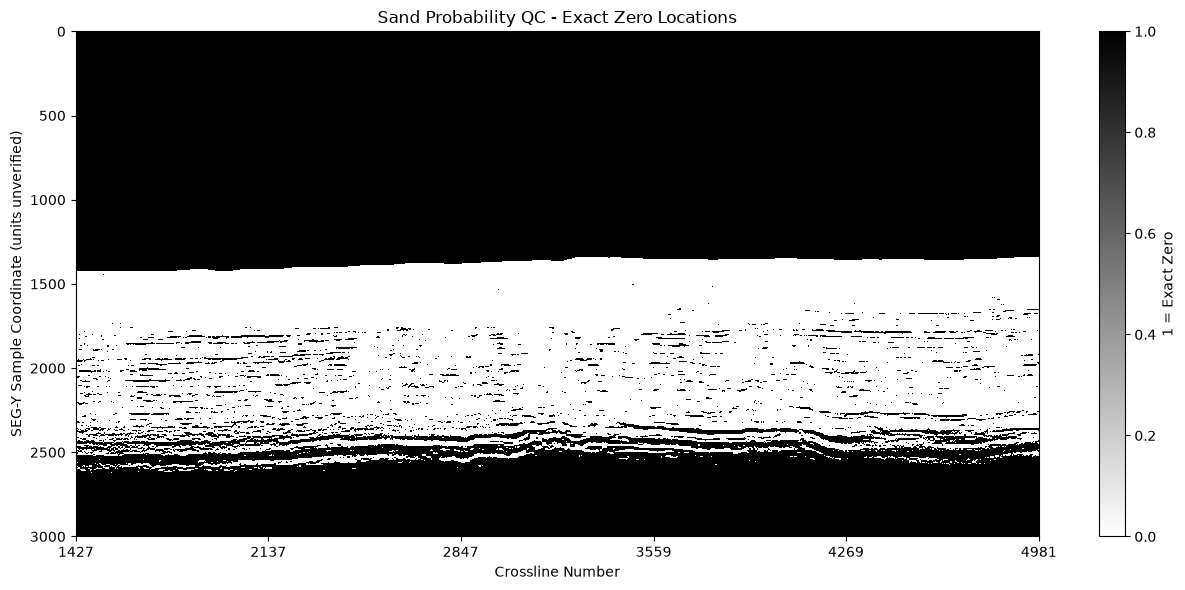

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Data from our previous seismic analysis
prob = sand_aligned

# Identify zero and nonzero values
valid = np.isfinite(prob)
zero_mask = valid & (prob == 0)

print("SAND PROBABILITY QUALITY CONTROL")
print("=" * 45)

print("Total samples:", prob.size)
print("Valid samples:", np.sum(valid))
print("Exact zero values:", np.sum(zero_mask))

print(
    "Zero percentage:",
    round(100 * np.sum(zero_mask) / np.sum(valid), 2),
    "%"
)

# Check where the zeros are concentrated
print("\nVERTICAL DISTRIBUTION")
print("=" * 45)

for start in range(0, 3000, 200):

    end = start + 200
    mask = (t2 >= start) & (t2 < end)

    block = prob[:, mask]
    values = block[np.isfinite(block)]

    if len(values) == 0:
        continue

    zero_pct = 100 * np.mean(values == 0)

    nonzero = values[values > 0]

    mean_nonzero = (
        np.mean(nonzero)
        if len(nonzero) > 0 else float("nan")
    )

    print(
        f"{start}-{end}: "
        f"Zeros = {zero_pct:.1f}% | "
        f"Nonzero mean = {mean_nonzero:.3f}"
    )

# Display where exact zeros occur
plt.figure(figsize=(13, 6))

plt.imshow(
    zero_mask.T,
    cmap="gray_r",
    aspect="auto",
    origin="upper",
    extent=[
        -0.5, len(common)-0.5,
        t2[-1], t2[0]
    ],
    interpolation="nearest"
)

ticks = np.linspace(
    0, len(common)-1, 6, dtype=int
)

plt.xticks(ticks, common[ticks])

plt.title(
    "Sand Probability QC - Exact Zero Locations"
)

plt.xlabel("Crossline Number")
plt.ylabel("SEG-Y Sample Coordinate (units unverified)")
plt.colorbar(label="1 = Exact Zero")
plt.tight_layout()
plt.show()


In [16]:

import pandas as pd
from pathlib import Path

file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data/"
    "Challenge1_Challenge2_WellList_Information.xlsx"
)

print("WELL LOCATION INFORMATION")
print("=" * 50)

if not file.exists():
    print("Well information file not found.")

else:
    excel = pd.ExcelFile(file)

    print("Available sheets:", excel.sheet_names)

    for sheet in excel.sheet_names:

        print("\nSHEET:", sheet)
        print("-" * 50)

        df = pd.read_excel(
            file,
            sheet_name=sheet,
            header=None
        )

        # Display first rows to inspect the format
        print("\nFIRST 10 ROWS:")
        print(
            df.iloc[:10, :12].to_string(
                index=False,
                header=False
            )
        )

        # Find information about well EO-1
        matches = df.astype(str).apply(
            lambda col: col.str.contains(
                r"eo[\s_-]*1",
                case=False,
                regex=True,
                na=False
            )
        ).any(axis=1)

        if matches.any():

            print("\nEO-1 INFORMATION:")

            print(
                df.loc[matches].to_string(
                    index=False,
                    header=False
                )
            )

        else:
            print("\nNo EO-1 match in this sheet.")


WELL LOCATION INFORMATION
Available sheets: ['Sheet1']

SHEET: Sheet1
--------------------------------------------------

FIRST 10 ROWS:
NaN       NaN    NaN NaN NaN     NaN        NaN         NaN         NaN        NaN        NaN     NaN
NaN       NaN    NaN NaN NaN     NaN        NaN         NaN         NaN        NaN        NaN     NaN
No. Well Name     RT  WD  WB      TD Well Types           X           Y Deviations Checkshots Markers
NaN       NaN    NaN NaN NaN     NaN        NaN         NaN         NaN        NaN        NaN     NaN
  1      eo-1  21.95 NaN NaN  3200.4     Marine   1374930.5   1796501.6          /          X       X
  2      eo-2     30 NaN NaN    3030     Marine  1375251.49  1797076.84          /          X       X
  3       m-1   29.4 NaN NaN    3927     Marine  1375995.01  1790506.35          /          /       X
  4      no-1     30 NaN NaN    3324     Marine  1369866.16  1798031.58          /          /       X
  5      no-2     17 NaN NaN    3160     Marine

In [17]:

import segyio
from pathlib import Path

seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

well_x = 1374930.50
well_y = 1796501.60

print("WELL EO-1")
print("X:", well_x)
print("Y:", well_y)

with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:

    total = f.tracecount

    # Inspect five locations across the survey
    positions = [
        0,
        total // 4,
        total // 2,
        3 * total // 4,
        total - 1
    ]

    print("\nSEISMIC TRACE COORDINATES")
    print("=" * 50)

    for i in positions:
        h = f.header[i]

        inline = int(
            h[segyio.TraceField.INLINE_3D]
        )

        crossline = int(
            h[segyio.TraceField.CROSSLINE_3D]
        )

        raw_x = int(
            h[segyio.TraceField.CDP_X]
        )

        raw_y = int(
            h[segyio.TraceField.CDP_Y]
        )

        scalar = int(
            h[segyio.TraceField.SourceGroupScalar]
        )

        # Apply standard SEG-Y coordinate scaling
        if scalar > 0:
            factor = scalar
        elif scalar < 0:
            factor = 1 / abs(scalar)
        else:
            factor = 1

        x = raw_x * factor
        y = raw_y * factor

        units = int(
            h[segyio.TraceField.CoordinateUnits]
        )

        print("\nTrace:", i)
        print("Inline:", inline)
        print("Crossline:", crossline)
        print("CDP X:", x)
        print("CDP Y:", y)
        print("Coordinate scalar:", scalar)
        print("Coordinate units code:", units)

    # Inspect the SEG-Y textual header
    print("\nSEISMIC TEXT HEADER")
    print("=" * 50)

    header_text = f.text[0]

    if isinstance(header_text, bytes):
        header_text = header_text.decode(
            "ascii", errors="replace"
        )

    print(header_text[:1600])


WELL EO-1
X: 1374930.5
Y: 1796501.6

SEISMIC TRACE COORDINATES

Trace: 0
Inline: 748
Crossline: 2101
CDP X: 1364647.3900000001
CDP Y: 1817168.36
Coordinate scalar: -100
Coordinate units code: 0

Trace: 363254
Inline: 1568
Crossline: 2555
CDP X: 1363417.25
CDP Y: 1805516.98
Coordinate scalar: -100
Coordinate units code: 0

Trace: 726509
Inline: 1988
Crossline: 4085
CDP X: 1376072.87
CDP Y: 1790246.3800000001
Coordinate scalar: -100
Coordinate units code: 0

Trace: 1089763
Inline: 2386
Crossline: 2745
CDP X: 1359498.16
CDP Y: 1795778.95
Coordinate scalar: -100
Coordinate units code: 0

Trace: 1453017
Inline: 3054
Crossline: 2871
CDP X: 1355988.92
CDP Y: 1788042.87
Coordinate scalar: -100
Coordinate units code: 0

SEISMIC TEXT HEADER
bytearray(b'C 1 APGCE 2026 GEOHACKATHON CHALLENGE 1 & 2                                     C 2 DATASET: FULL STACK IN TIME DOMAIN                                          C 3 INLINE: 748-3054                CROSSLINE: 1181-4981                        C 4 FOR

In [18]:

import segyio
import numpy as np
from pathlib import Path

# EO-1 wellhead coordinates
well_x = 1374930.50
well_y = 1796501.60

seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

print("SEARCHING FOR THE NEAREST SEISMIC TRACE...")

with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:

    # Read seismic trace positions
    raw_x = np.asarray(
        f.attributes(segyio.TraceField.CDP_X)[:],
        dtype=float
    )

    raw_y = np.asarray(
        f.attributes(segyio.TraceField.CDP_Y)[:],
        dtype=float
    )

    scalars = np.asarray(
        f.attributes(
            segyio.TraceField.SourceGroupScalar
        )[:],
        dtype=float
    )

    # Apply SEG-Y coordinate scalars
    factor = np.ones_like(scalars)

    positive = scalars > 0
    negative = scalars < 0

    factor[positive] = scalars[positive]
    factor[negative] = (
        1.0 / np.abs(scalars[negative])
    )

    x = raw_x * factor
    y = raw_y * factor

    # Exclude missing coordinates
    valid = (
        np.isfinite(x) &
        np.isfinite(y) &
        (raw_x != 0) &
        (raw_y != 0)
    )

    if not np.any(valid):
        raise ValueError(
            "No valid seismic coordinates found."
        )

    # Calculate squared planar distances
    distance_squared = (
        (x - well_x)**2 +
        (y - well_y)**2
    )

    distance_squared[~valid] = np.inf

    # Find nearest seismic trace
    nearest = int(np.argmin(distance_squared))

    h = f.header[nearest]

    nearest_inline = int(
        h[segyio.TraceField.INLINE_3D]
    )

    nearest_crossline = int(
        h[segyio.TraceField.CROSSLINE_3D]
    )

    distance = np.sqrt(
        distance_squared[nearest]
    )

print("\nNEAREST SEISMIC TRACE TO EO-1")
print("=" * 45)

print("Well: EO-1")
print("Well X:", well_x)
print("Well Y:", well_y)

print("\nNearest trace index:", nearest)
print("Nearest inline:", nearest_inline)
print("Nearest crossline:", nearest_crossline)

print("\nSeismic trace X:", round(x[nearest], 2))
print("Seismic trace Y:", round(y[nearest], 2))

print("\nCoordinate distance:", round(distance, 2))

print("\nIMPORTANT:")
print("Distance is in survey coordinate units.")
print("CRS and units must be verified.")
print("This is a wellhead tie, not a depth tie.")


SEARCHING FOR THE NEAREST SEISMIC TRACE...

NEAREST SEISMIC TRACE TO EO-1
Well: EO-1
Well X: 1374930.5
Well Y: 1796501.6

Nearest trace index: 415958
Nearest inline: 1630
Nearest crossline: 3723

Seismic trace X: 1374932.76
Seismic trace Y: 1796507.58

Coordinate distance: 6.39

IMPORTANT:
Distance is in survey coordinate units.
CRS and units must be verified.
This is a wellhead tie, not a depth tie.


In [19]:

from pathlib import Path

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data"
)

# STEP 1: Inspect EO-1 deviation survey
deviation_file = base / "deviations" / "eo-1_Deviation.txt"

print("=" * 55)
print("EO-1 WELL DEVIATION DATA")
print("=" * 55)

if deviation_file.exists():

    print("Deviation file found!\n")

    with open(deviation_file, errors="replace") as f:
        for i, line in enumerate(f):
            if i >= 30:
                break
            print(line.rstrip())

else:
    print("Deviation file not found.")

# STEP 2: Search for possible time-depth information
print("\n" + "=" * 55)
print("SEARCHING FOR TIME-DEPTH DATA")
print("=" * 55)

keywords = [
    "checkshot",
    "check_shot",
    "velocity",
    "time_depth",
    "timedepth",
    "sonic",
    "vsp"
]

matches = []

for file in base.rglob("*"):
    if file.is_file():
        name = file.name.lower()

        if any(word in name for word in keywords):
            matches.append(file)

if matches:
    for file in matches:
        print(file.relative_to(base))
else:
    print("No matching file names found.")

# STEP 3: Check EO-1's LAS curve names
print("\n" + "=" * 55)
print("EO-1 LOG CURVES")
print("=" * 55)

las_file = base / "las" / "eo-1.las"

if las_file.exists():
    reading_curves = False

    with open(las_file, errors="replace") as f:
        for line in f:
            line = line.strip()

            if line.upper().startswith("~C"):
                reading_curves = True
                continue

            if reading_curves and line.startswith("~"):
                break

            if reading_curves and line and not line.startswith("#"):
                print(line)


EO-1 WELL DEVIATION DATA
Deviation file found!

#eo-1
#Deviation
#MDKB (m)
#AZIM
#INCL
0 0 0
626.06 11.9894787 0.2
799.19 334.9719162 0.2
1115.87 230.0164571 0.5
1355.45 254.9887811 0.5
1518.82 230.1515246 0.5
1691.03 282.9906483 2.2
1948.89 200.0355386 2.7
2121.71 259.9597256 2.2
2400.91 265.0028887 2.7
2578.61 286.9746802 1.2
2896.21 281.0018378 1.5
3200.4 281 1.5

SEARCHING FOR TIME-DEPTH DATA
checkshots/no-1_Checkshot.txt
checkshots/p-1_Checkshot.txt
checkshots/m-1_Checkshot.txt

EO-1 LOG CURVES
DEPTH.M                    :
VSH  .V/V                  :  Shale volume - VCLAY+VOL_CBW+VSILT
PHIT .V/V                  :  Limited total porosity
SWT  .V/V                  :  Total Sw - Limited
PS_GIP.MV                   :  Flag calculated by tp_paysummary
PS_OIP.MV                   :  Flag calculated by tp_paysummary


In [20]:

from pathlib import Path
import re

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data"
)

wells = ["no-1", "p-1", "m-1"]

print("EXPLORATION COPILOT")
print("WELL COMPARISON REPORT")
print("=" * 60)

for well in wells:

    print("\n" + "=" * 60)
    print("WELL:", well.upper())
    print("=" * 60)

    checkshot = (
        base / "checkshots" /
        f"{well}_Checkshot.txt"
    )

    las_file = base / "las" / f"{well}.las"

    # PART 1: CHECKSHOT INFORMATION
    print("\n1. CHECKSHOT SURVEY")

    if checkshot.exists():

        lines = checkshot.read_text(
            errors="replace"
        ).splitlines()

        print("File found: YES")

        print("\nFIRST 12 LINES:")
        for line in lines[:12]:
            print(line)

        # Extract rows containing numerical values
        data_rows = []

        for line in lines:

            line = line.strip()

            if not line or line.startswith("#"):
                continue

            parts = re.split(r"[\s,;]+", line)

            try:
                values = [
                    float(part) for part in parts
                ]

                if len(values) >= 2:
                    data_rows.append(values)

            except ValueError:
                continue

        print("\nNumerical rows:", len(data_rows))

        if data_rows:
            print("First numerical row:", data_rows[0])
            print("Last numerical row:", data_rows[-1])

    else:
        print("Checkshot file not found.")

    # PART 2: WELL LOG INFORMATION
    print("\n2. AVAILABLE WELL LOGS")

    if las_file.exists():

        print("LAS file found: YES")

        reading_curves = False
        curve_names = []

        with open(
            las_file, errors="replace"
        ) as f:

            for line in f:

                line = line.strip()

                if line.upper().startswith("~C"):
                    reading_curves = True
                    continue

                if reading_curves and line.startswith("~"):
                    break

                if reading_curves and line and not line.startswith("#"):

                    name = line.split(".")[0].strip()
                    curve_names.append(name)

        print("Available curves:", curve_names)

        for curve in ["VSH", "PHIT", "SWT"]:

            if curve in curve_names:
                print(curve, ": AVAILABLE")
            else:
                print(curve, ": NOT FOUND")

    else:
        print("LAS file not found.")

print("\nCOMPARISON COMPLETED!")


EXPLORATION COPILOT
WELL COMPARISON REPORT

WELL: NO-1

1. CHECKSHOT SURVEY
File found: YES

FIRST 12 LINES:
#no-1
#Checkshot
#TVDSS (m)
#TWT (ms)
0	0
220	266.4
269.9	324.4
320	383
370	441.3
420	494.9
469.9	547.3
519.9	599.2

Numerical rows: 118
First numerical row: [0.0, 0.0]
Last numerical row: [3066.1, 2363.1]

2. AVAILABLE WELL LOGS
LAS file found: YES
Available curves: ['DEPTH', 'VSH', 'PHIT', 'SWT', 'PS_GIP', 'PS_OIP']
VSH : AVAILABLE
PHIT : AVAILABLE
SWT : AVAILABLE

WELL: P-1

1. CHECKSHOT SURVEY
File found: YES

FIRST 12 LINES:
#p-1
#Checkshot
#TVDSS (m)
#TWT (ms)
0	0
1.52	2
3.05	4
4.57	6
6.1	8
7.62	10
9.14	12
12.19	16

Numerical rows: 1351
First numerical row: [0.0, 0.0]
Last numerical row: [3676.8, 2714.0]

2. AVAILABLE WELL LOGS
LAS file found: YES
Available curves: ['DEPTH', 'VSH', 'PHIT', 'SWT', 'PS_GIP', 'PS_OIP']
VSH : AVAILABLE
PHIT : AVAILABLE
SWT : AVAILABLE

WELL: M-1

1. CHECKSHOT SURVEY
File found: YES

FIRST 12 LINES:
#m-1
#Checkshot
#TVDSS (m)
#TWT (ms)
0	0
270.

In [21]:

from pathlib import Path
import numpy as np

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data"
)

well = "p-1"

checkshot_file = (
    base / "checkshots" / "p-1_Checkshot.txt"
)

las_file = base / "las" / "p-1.las"

deviation_file = (
    base / "deviations" / "p-1_Deviation.txt"
)

# PART 1 - CHECKSHOT QUALITY CONTROL

depths_cs = []
times_cs = []

for line in checkshot_file.read_text().splitlines():

    line = line.strip()

    if not line or line.startswith("#"):
        continue

    values = line.replace(",", " ").split()

    try:
        d = float(values[0])
        t = float(values[1])

        depths_cs.append(d)
        times_cs.append(t)

    except (ValueError, IndexError):
        continue

depths_cs = np.array(depths_cs)
times_cs = np.array(times_cs)

print("=" * 55)
print("P-1 CHECKSHOT QUALITY CONTROL")
print("=" * 55)

print("Number of rows:", len(depths_cs))
print("Maximum TVDSS (m):", depths_cs.max())
print("Maximum TWT (ms):", times_cs.max())

print(
    "Depth strictly increasing:",
    bool(np.all(np.diff(depths_cs) > 0))
)

print(
    "Time strictly increasing:",
    bool(np.all(np.diff(times_cs) > 0))
)

print(
    "First 10 TWT increments:",
    np.diff(times_cs)[:10]
)

print(
    "Median TWT increment (ms):",
    np.median(np.diff(times_cs))
)

# PART 2 - WELL LOG METADATA

print("\n" + "=" * 55)
print("P-1 LAS WELL INFORMATION")
print("=" * 55)

in_well_section = False

with open(las_file, errors="replace") as f:

    for line in f:

        clean = line.strip()

        if clean.upper().startswith("~W"):
            in_well_section = True
            continue

        if in_well_section and clean.startswith("~"):
            break

        if in_well_section:
            print(clean)

# PART 3 - WELL DEVIATION

print("\n" + "=" * 55)
print("P-1 DEVIATION SURVEY")
print("=" * 55)

if deviation_file.exists():

    lines = deviation_file.read_text(
        errors="replace"
    ).splitlines()

    print("\nFIRST 12 LINES")

    for line in lines[:12]:
        print(line)

    print("\nLAST 5 LINES")

    for line in lines[-5:]:
        print(line)

else:
    print("Deviation file not found.")


P-1 CHECKSHOT QUALITY CONTROL
Number of rows: 1351
Maximum TVDSS (m): 3676.8
Maximum TWT (ms): 2714.0
Depth strictly increasing: True
Time strictly increasing: True
First 10 TWT increments: [2. 2. 2. 2. 2. 2. 4. 2. 2. 2.]
Median TWT increment (ms): 2.0

P-1 LAS WELL INFORMATION
#MNEM.UNIT        Data Type   Information
#---------- ----------------  -----------
STRT .M          1390.65000:  START DEPTH
STOP .M          3610.81320:  STOP DEPTH
STEP .M             0.15240:  STEP
NULL .              -999.25:  NULL VALUE
COMP .                     :  COMPANY
WELL .                  p-1:  WELL
FLD  .                     :  FIELD
LOC  .                     :  LOCATION
CTRY .                     :  COUNTRY
STAT .                     :  STATE
CNTY .                     :  COUNTY
SRVC .                     :  SERVICE COMPANY
DATE .                     :  DATE
API  .                     :  API NUMBER
UWI  .                     :  UNIQUE WELL ID

P-1 DEVIATION SURVEY

FIRST 12 LINES
#p-1
#Deviatio

In [22]:

import pandas as pd
from pathlib import Path
from openpyxl.utils import get_column_letter

file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data/"
    "Challenge1_Challenge2_WellList_Information.xlsx"
)

excel = pd.ExcelFile(file)

print("=" * 55)
print("P-1 WELL INFORMATION")
print("=" * 55)

found = False

for sheet in excel.sheet_names:

    df = pd.read_excel(
        file,
        sheet_name=sheet,
        header=None,
        dtype=str
    )

    # Find cells containing exactly P-1
    mask = df.apply(
        lambda col: (
            col.fillna("")
            .str.strip()
            .str.lower()
            .eq("p-1")
        )
    ).any(axis=1)

    for row_index in df.index[mask]:

        found = True

        print("\nSHEET:", sheet)
        print("EXCEL ROW:", row_index + 1)

        print("\nP-1 DATA:")

        for col_index, value in enumerate(
            df.iloc[row_index]
        ):

            if pd.isna(value):
                continue

            if not str(value).strip():
                continue

            # Show possible column headers
            headers = []

            for header_row in range(min(row_index, 5)):
                heading = df.iat[
                    header_row, col_index
                ]

                if pd.notna(heading):
                    headers.append(str(heading))

            label = " / ".join(headers)

            print(
                f"Column {get_column_letter(col_index+1)}"
                f" | {label or 'Unlabelled'}"
                f" | {value}"
            )

if not found:
    print("P-1 not found in the spreadsheet.")


P-1 WELL INFORMATION

SHEET: Sheet1
EXCEL ROW: 16

P-1 DATA:
Column A | No. / 1 | 12
Column B | Well Name / eo-1 | p-1
Column C | RT / 21.95 | 22.25
Column F | TD / 3200.4 | 3615
Column G | Well Types / Marine | Marine
Column H | X / 1374930.5 | 1361717
Column I | Y / 1796501.6 | 1797578
Column J | Deviations / / | /
Column K | Checkshots / X | /
Column L | Markers / X | X
Column M | Las / / | /


In [23]:

import segyio
import numpy as np
from pathlib import Path

# P-1 coordinates from the well spreadsheet
well_x = 1361717.0
well_y = 1797578.0

seismic_file = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/stack/"
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

print("SEARCHING FOR P-1 NEAREST SEISMIC TRACE...")

with segyio.open(
    str(seismic_file),
    "r",
    ignore_geometry=True
) as f:

    # Read all seismic trace coordinates
    raw_x = np.asarray(
        f.attributes(segyio.TraceField.CDP_X)[:],
        dtype=np.float64
    )

    raw_y = np.asarray(
        f.attributes(segyio.TraceField.CDP_Y)[:],
        dtype=np.float64
    )

    scalar = np.asarray(
        f.attributes(
            segyio.TraceField.SourceGroupScalar
        )[:],
        dtype=np.float64
    )

    # Apply SEG-Y coordinate scaling
    factor = np.ones_like(scalar)

    factor[scalar > 0] = scalar[scalar > 0]
    factor[scalar < 0] = (
        1.0 / np.abs(scalar[scalar < 0])
    )

    seismic_x = raw_x * factor
    seismic_y = raw_y * factor

    valid = (
        np.isfinite(seismic_x) &
        np.isfinite(seismic_y) &
        (raw_x != 0) &
        (raw_y != 0)
    )

    if not np.any(valid):
        raise ValueError(
            "No valid seismic coordinates found."
        )

    # Calculate coordinate separation
    distance_sq = (
        (seismic_x - well_x)**2 +
        (seismic_y - well_y)**2
    )

    distance_sq[~valid] = np.inf

    # Locate nearest seismic trace
    nearest = int(np.argmin(distance_sq))

    header = f.header[nearest]

    nearest_inline = int(
        header[segyio.TraceField.INLINE_3D]
    )

    nearest_crossline = int(
        header[segyio.TraceField.CROSSLINE_3D]
    )

    distance = np.sqrt(distance_sq[nearest])

print("\n" + "=" * 55)
print("P-1 NEAREST SEISMIC TRACE")
print("=" * 55)

print("Well:", "P-1")

print("\nWell X:", well_x)
print("Well Y:", well_y)

print("\nNearest inline:", nearest_inline)
print("Nearest crossline:", nearest_crossline)
print("Trace index:", nearest)

print("\nSeismic X:", round(seismic_x[nearest], 2))
print("Seismic Y:", round(seismic_y[nearest], 2))

print(
    "\nCoordinate separation:",
    round(distance, 2),
    "survey coordinate units"
)

print("\nIMPORTANT:")
print("Confirm matching coordinate reference systems.")
print("This is the nearest wellhead location only.")
print("Vertical well-to-seismic tie is not yet validated.")


SEARCHING FOR P-1 NEAREST SEISMIC TRACE...

P-1 NEAREST SEISMIC TRACE
Well: P-1

Well X: 1361717.0
Well Y: 1797578.0

Nearest inline: 2166
Nearest crossline: 2807
Trace index: 886170

Seismic X: 1361710.31
Seismic Y: 1797587.05

Coordinate separation: 11.25 survey coordinate units

IMPORTANT:
Confirm matching coordinate reference systems.
This is the nearest wellhead location only.
Vertical well-to-seismic tie is not yet validated.


LOADING P-1 SEISMIC DATA...

P-1 SEISMIC INFORMATION
Inline: 2166
P-1 nearest full-stack crossline: 2807
Nearest matched crossline: 2807
Matching traces: 301
TWT range: 0.0 3000.0
Sand attribute range: 0.0 0.99998224


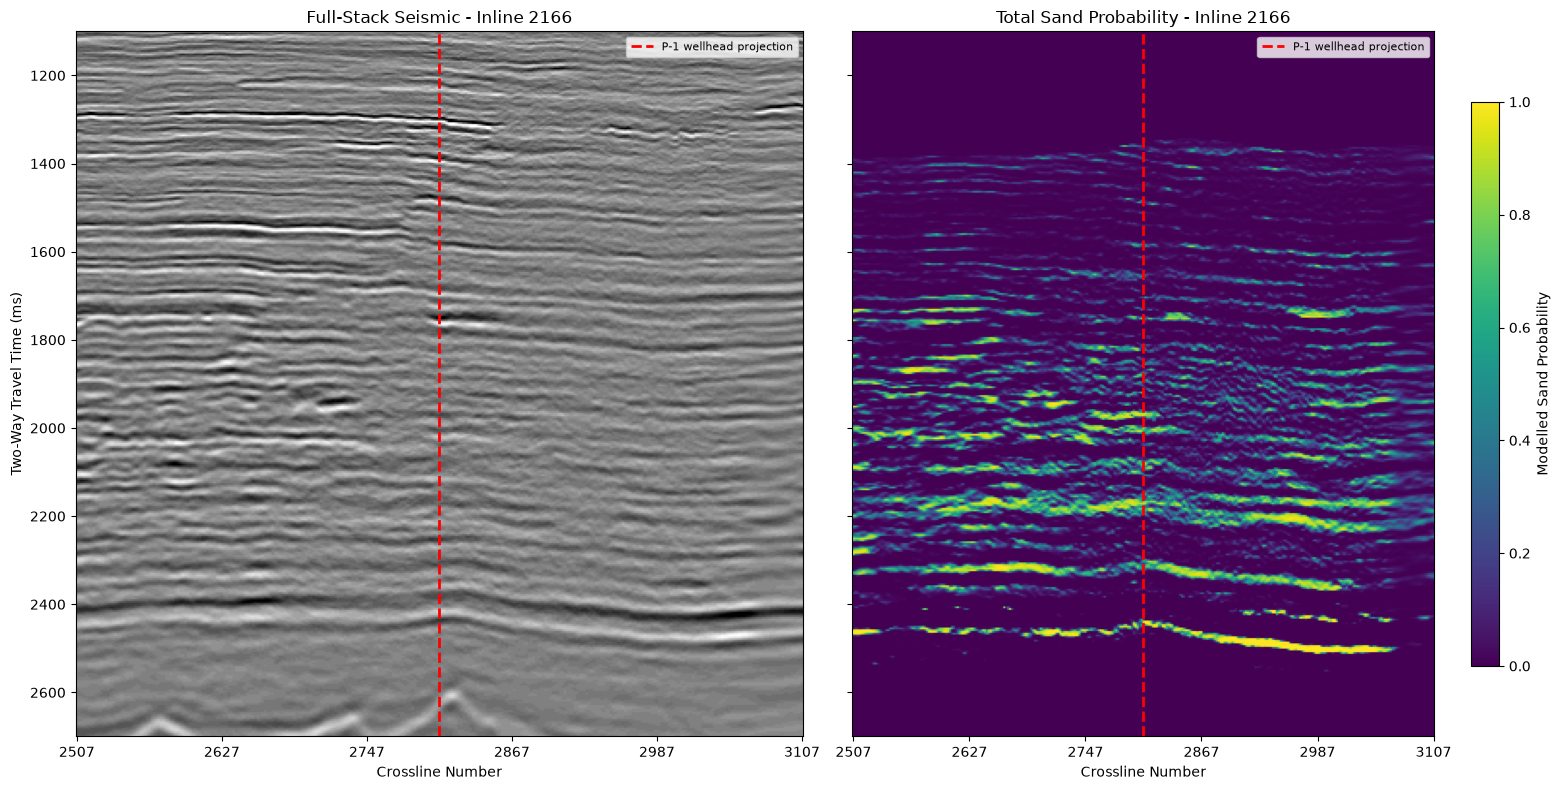


P-1 SEISMIC VISUALISATION COMPLETE!
Red line marks the approximate wellhead position.
It is NOT a calibrated depth-to-time well tie.


In [24]:

import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# P-1 location from your previous results
target_inline = 2166
well_crossline = 2807

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2"
)

stack_path = base / "stack" / (
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

sand_path = base / "inversion" / (
    "Challenge1_Challenge2_Inversion_TotalSandProbability_cropped.sgy"
)

# Read a limited area around P-1
def read_section(path, inline, center, width=300):

    with segyio.open(
        str(path), "r", ignore_geometry=True
    ) as f:

        inlines = f.attributes(
            segyio.TraceField.INLINE_3D
        )[:]

        indices = np.where(inlines == inline)[0]

        if len(indices) == 0:
            raise ValueError(
                f"Inline {inline} not found in {path.name}"
            )

        crosslines = f.attributes(
            segyio.TraceField.CROSSLINE_3D
        )[indices]

        keep = np.abs(crosslines - center) <= width

        indices = indices[keep]
        crosslines = crosslines[keep]

        if len(indices) == 0:
            raise ValueError(
                "No traces found near P-1."
            )

        order = np.argsort(
            crosslines, kind="stable"
        )

        indices = indices[order]
        crosslines = crosslines[order]

        unique_x, first = np.unique(
            crosslines, return_index=True
        )

        indices = indices[first]

        traces = np.stack([
            np.copy(f.trace[int(i)])
            for i in indices
        ])

        samples = np.asarray(f.samples).copy()

    return unique_x, samples, traces


print("LOADING P-1 SEISMIC DATA...")

x1, t1, full = read_section(
    stack_path, target_inline, well_crossline
)

x2, t2, sand = read_section(
    sand_path, target_inline, well_crossline
)

# Match actual crossline and time coordinates
common_x = np.intersect1d(x1, x2)
common_t = np.intersect1d(t1, t2)

if len(common_x) < 2 or len(common_t) < 2:
    raise ValueError(
        "Insufficient matching seismic coordinates."
    )

full = full[
    np.searchsorted(x1, common_x)
][:, np.searchsorted(t1, common_t)]

sand = sand[
    np.searchsorted(x2, common_x)
][:, np.searchsorted(t2, common_t)]

# Find wellhead's nearest matching crossline
well_index = int(np.argmin(
    np.abs(common_x - well_crossline)
))

selected_xline = int(common_x[well_index])

print("\nP-1 SEISMIC INFORMATION")
print("=" * 45)
print("Inline:", target_inline)
print("P-1 nearest full-stack crossline:",
      well_crossline)
print("Nearest matched crossline:", selected_xline)
print("Matching traces:", len(common_x))
print("TWT range:", common_t[0], common_t[-1])
print("Sand attribute range:",
      np.nanmin(sand), np.nanmax(sand))

# Prepare seismic amplitude scale
clip = np.nanpercentile(np.abs(full), 99)

if not np.isfinite(clip) or clip <= 0:
    clip = 1.0

# Plot both sections
fig, axes = plt.subplots(
    1, 2, figsize=(16, 8), sharey=True
)

extent = [
    -0.5,
    len(common_x) - 0.5,
    common_t[-1],
    common_t[0]
]

axes[0].imshow(
    full.T,
    cmap="gray",
    aspect="auto",
    origin="upper",
    extent=extent,
    vmin=-clip,
    vmax=clip
)

axes[0].set_title(
    "Full-Stack Seismic - Inline 2166"
)

im = axes[1].imshow(
    sand.T,
    cmap="viridis",
    aspect="auto",
    origin="upper",
    extent=extent,
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "Total Sand Probability - Inline 2166"
)

# Mark P-1's approximate wellhead position
for ax in axes:

    ax.axvline(
        well_index,
        color="red",
        linestyle="--",
        linewidth=2,
        label="P-1 wellhead projection"
    )

    ticks = np.linspace(
        0, len(common_x)-1, 6, dtype=int
    )

    ax.set_xticks(ticks)
    ax.set_xticklabels(common_x[ticks])
    ax.set_xlabel("Crossline Number")
    ax.legend(loc="upper right", fontsize=8)

    # Focus on the main inversion window
    ax.set_ylim(2700, 1100)

axes[0].set_ylabel(
    "Two-Way Travel Time (ms)"
)

fig.colorbar(
    im,
    ax=axes[1],
    label="Modelled Sand Probability",
    shrink=0.8
)

plt.tight_layout()
plt.show()

print("\nP-1 SEISMIC VISUALISATION COMPLETE!")
print("Red line marks the approximate wellhead position.")
print("It is NOT a calibrated depth-to-time well tie.")


P-1 PROVISIONAL WELL-TO-SEISMIC COMPARISON
Valid well-log samples: 12932
LAS depth range: 1390.65 3599.3832
Scenario A TWT range: 1327.2884615384617 2653.5751219512194
Scenario B TWT range: 1344.1260504201682 2666.937540106952
Nearest seismic crossline: 2807


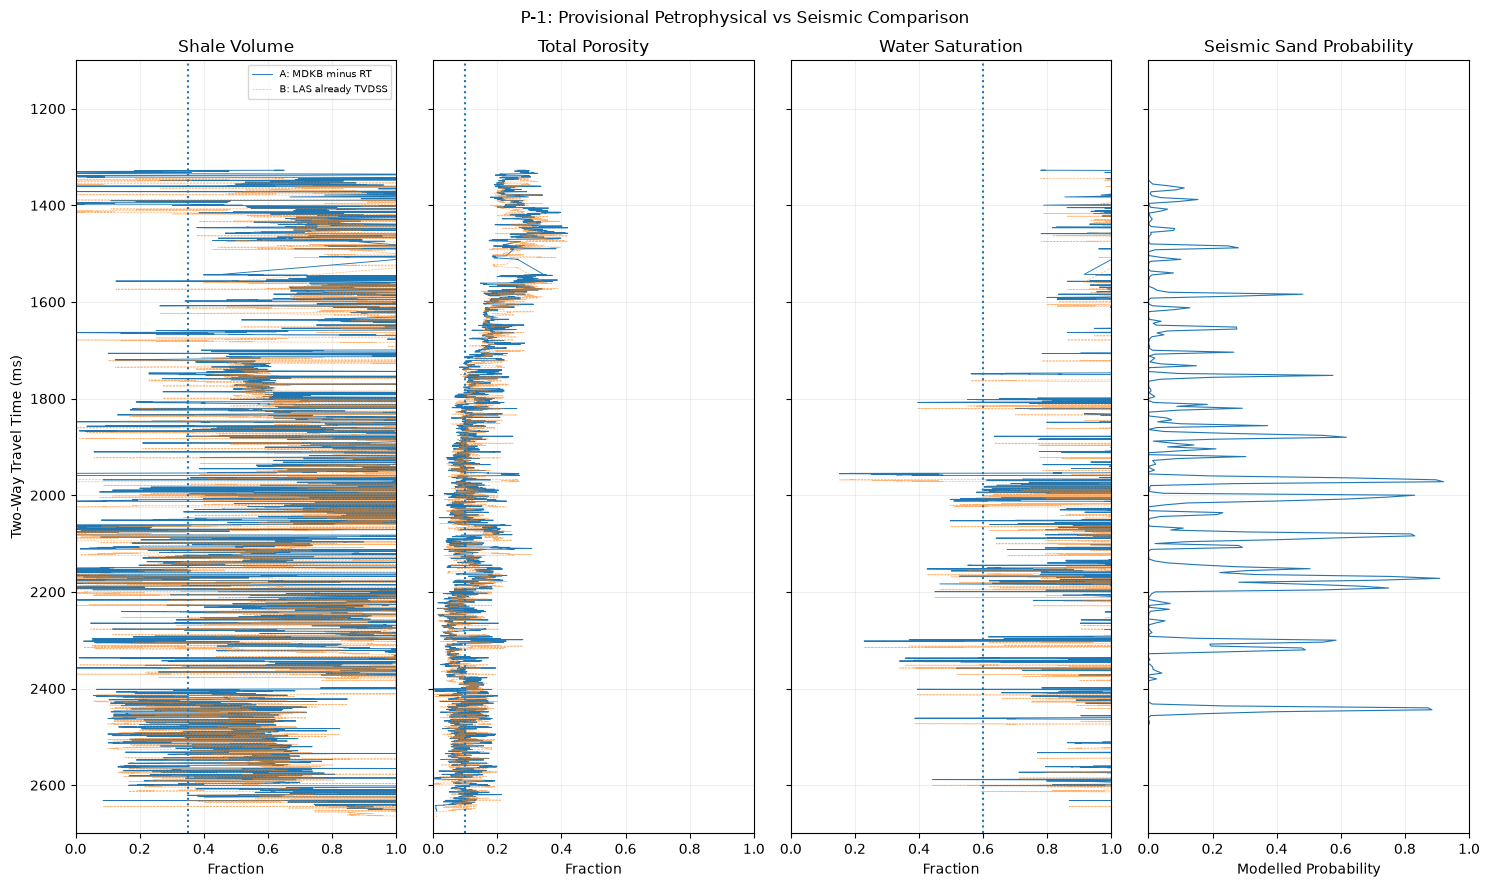


IMPORTANT:
Depth datum scenarios are not yet verified.
Zeros in sand probability may represent masking.
This is NOT a calibrated synthetic seismic tie.


In [25]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data"
)

# 1. Read P-1 checkshot: TVDSS (m), TWT (ms)
cs_depth = []
cs_time = []

with open(base / "checkshots/p-1_Checkshot.txt") as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        try:
            d, t = map(float, line.split()[:2])
            cs_depth.append(d)
            cs_time.append(t)
        except (ValueError, IndexError):
            continue

cs_depth = np.array(cs_depth)
cs_time = np.array(cs_time)

assert np.all(np.diff(cs_depth) > 0)
assert np.all(np.diff(cs_time) > 0)

# 2. Read P-1 petrophysical logs
records = []
reading = False

with open(base / "las/p-1.las", errors="replace") as f:
    for line in f:
        line = line.strip()

        if line.upper().startswith("~A"):
            reading = True
            continue

        if not reading or not line or line.startswith("#"):
            continue

        if line.startswith("~"):
            break

        try:
            d, v, p, s = map(float, line.split()[:4])

            if 0 <= v <= 1 and 0 <= p <= 1 and 0 <= s <= 1:
                records.append((d, v, p, s))

        except (ValueError, IndexError):
            continue

if not records:
    raise ValueError("No valid P-1 log data found.")

data = np.array(records)

log_depth = data[:, 0]
vsh = data[:, 1]
phit = data[:, 2]
swt = data[:, 3]

# 3. Two possible depth-reference scenarios
# A: LAS depth is MDKB; RT is 22.25 m above MSL
# B: LAS depth is already TVDSS
# These are assumptions to test, NOT verified datums.

rt = 22.25

twt_a = np.interp(log_depth - rt, cs_depth, cs_time)
twt_b = np.interp(log_depth, cs_depth, cs_time)

# 4. Use the actual P-1 seismic trace
# These variables come from your previous cell.
sand_trace = sand[well_index, :]

print("P-1 PROVISIONAL WELL-TO-SEISMIC COMPARISON")
print("=" * 50)
print("Valid well-log samples:", len(log_depth))
print("LAS depth range:", log_depth.min(), log_depth.max())
print("Scenario A TWT range:", twt_a.min(), twt_a.max())
print("Scenario B TWT range:", twt_b.min(), twt_b.max())
print("Nearest seismic crossline:", selected_xline)

# 5. Plot well logs and sand probability
fig, axes = plt.subplots(
    1, 4, figsize=(15, 9), sharey=True
)

curves = [
    (vsh, "Shale Volume", 0.35),
    (phit, "Total Porosity", 0.10),
    (swt, "Water Saturation", 0.60)
]

for ax, (curve, title, cutoff) in zip(axes[:3], curves):

    ax.plot(
        curve, twt_a,
        linewidth=0.65,
        label="A: MDKB minus RT"
    )

    ax.plot(
        curve, twt_b,
        linestyle="--",
        linewidth=0.45,
        alpha=0.6,
        label="B: LAS already TVDSS"
    )

    ax.axvline(cutoff, linestyle=":")
    ax.set_title(title)
    ax.set_xlabel("Fraction")
    ax.set_xlim(0, 1)
    ax.grid(alpha=0.2)

axes[3].plot(
    sand_trace,
    common_t,
    linewidth=0.8
)

axes[3].set_title("Seismic Sand Probability")
axes[3].set_xlabel("Modelled Probability")
axes[3].set_xlim(0, 1)
axes[3].grid(alpha=0.2)

axes[0].set_ylabel("Two-Way Travel Time (ms)")
axes[0].set_ylim(2700, 1100)
axes[0].legend(fontsize=7)

fig.suptitle(
    "P-1: Provisional Petrophysical vs Seismic Comparison"
)

plt.tight_layout()
plt.show()

print("\nIMPORTANT:")
print("Depth datum scenarios are not yet verified.")
print("Zeros in sand probability may represent masking.")
print("This is NOT a calibrated synthetic seismic tie.")


In [26]:

import numpy as np
import pandas as pd
import json
import urllib.request

print("EXPLORATION COPILOT")
print("INTEGRATED WELL-SEISMIC ANALYSIS")
print("=" * 55)

# These variables come from Step 24:
# twt_a, twt_b, vsh, phit, swt
# common_t, sand, well_index

sand_trace = np.asarray(
    sand[well_index], dtype=float
)

seismic_time = np.asarray(
    common_t, dtype=float
)

# Compare both provisional depth-datum scenarios
scenarios = {
    "A_MDKB_minus_RT": twt_a,
    "B_LAS_already_TVDSS": twt_b
}

all_results = []

# 100 ms seismic-time windows
time_bins = np.arange(1400, 2601, 100)

for scenario_name, well_time in scenarios.items():

    for start, end in zip(
        time_bins[:-1], time_bins[1:]
    ):

        # Select well samples in this time window
        well_mask = (
            (well_time >= start) &
            (well_time < end)
        )

        # Select seismic samples in same window
        seismic_mask = (
            (seismic_time >= start) &
            (seismic_time < end)
        )

        if np.sum(well_mask) < 10:
            continue

        v = np.asarray(vsh)[well_mask]
        p = np.asarray(phit)[well_mask]
        s = np.asarray(swt)[well_mask]

        probabilities = sand_trace[seismic_mask]
        probabilities = probabilities[
            np.isfinite(probabilities)
        ]

        if len(probabilities) == 0:
            continue

        nonzero = probabilities[
            probabilities > 0
        ]

        # Illustrative petrophysical screening
        screening = (
            (v < 0.35) &
            (p >= 0.10) &
            (s < 0.60)
        )

        result = {
            "scenario": scenario_name,
            "twt_interval_ms": f"{start}-{end}",
            "well_samples": int(len(v)),
            "mean_vsh": round(float(np.mean(v)), 3),
            "mean_phit": round(float(np.mean(p)), 3),
            "mean_swt": round(float(np.mean(s)), 3),
            "well_screening_fraction": round(
                float(np.mean(screening)), 3
            ),
            "sand_probability_nonzero_mean": (
                round(float(np.mean(nonzero)), 3)
                if len(nonzero) else None
            ),
            "sand_probability_high_fraction": round(
                float(np.mean(probabilities >= 0.6)), 3
            ),
            "sand_zero_fraction": round(
                float(np.mean(probabilities == 0)), 3
            )
        }

        all_results.append(result)

# Display numerical evidence
df = pd.DataFrame(all_results)

print("\nINTEGRATED GEOLOGICAL EVIDENCE")
display(df)

# Send the actual results to Gemma
prompt = f"""
You are an AI petroleum exploration geoscientist.

Analyse the following numerical evidence from
Well P-1 and its nearby seismic inversion trace.

DATA:
{json.dumps(all_results, indent=2)}

The well data includes:
- VSH: shale volume
- PHIT: total porosity
- SWT: total water saturation

The seismic data includes:
- Modelled Total Sand Probability

The analysis uses 100 ms time windows.

Two provisional depth-reference scenarios
have been tested:
A: LAS depth assumed MDKB minus RT 22.25 m
B: LAS depth assumed already TVDSS

IMPORTANT LIMITATIONS:
- Neither depth datum scenario is confirmed.
- The checkshot and seismic datums need QC.
- Zero sand probabilities may include masking.
- Nonzero means exclude exact zeros and
  may therefore be biased.
- Well screening thresholds are illustrative.
- No synthetic seismic tie has been calibrated.

TASKS:

1. Identify time windows where the well
   and seismic data appear consistent.

2. Identify windows where they may disagree.

3. Explain which observations suggest
   relatively sand-prone intervals.

4. Compare interpretations under
   scenarios A and B.

5. Explain the geological uncertainties.

6. Recommend what to investigate next
   before evaluating a hydrocarbon trap.

RULES:
- Use only supplied numerical evidence.
- Do not invent faults or stratigraphic pinch-outs.
- Do not claim confirmed hydrocarbons.
- Do not present this as a calibrated well tie.
- Separate observations, hypotheses and
  recommendations.
- Quote the relevant seismic time windows.

Respond as an experienced petroleum geoscientist.
"""

payload = {
    "model": "google/gemma-4-26B-A4B-it",
    "messages": [
        {
            "role": "system",
            "content": (
                "You are Exploration Copilot. "
                "Provide evidence-based geological "
                "interpretations and uncertainties."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    "temperature": 0.2
}

req = urllib.request.Request(
    "http://172.28.34.1:8000/v1/chat/completions",
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(
    req, timeout=120
) as response:
    ai_result = json.load(response)

print("\n" + "=" * 55)
print("AI INTEGRATED GEOLOGICAL INTERPRETATION")
print("=" * 55)

print(
    ai_result["choices"][0]["message"]["content"]
)


EXPLORATION COPILOT
INTEGRATED WELL-SEISMIC ANALYSIS

INTEGRATED GEOLOGICAL EVIDENCE


,scenario,twt_interval_ms,well_samples,mean_vsh,mean_phit,mean_swt,well_screening_fraction,sand_probability_nonzero_mean,sand_probability_high_fraction,sand_zero_fraction
0,A_MDKB_minus_RT,1400-1500,632,0.770,0.297,0.995,0.000,0.036,0.00,0.00
1,A_MDKB_minus_RT,1500-1600,473,0.828,0.240,0.994,0.000,0.045,0.00,0.00
2,A_MDKB_minus_RT,1600-1700,756,0.897,0.179,0.999,0.000,0.041,0.00,0.00
3,A_MDKB_minus_RT,1700-1800,928,0.595,0.133,0.989,0.003,0.059,0.00,0.00
4,A_MDKB_minus_RT,1800-1900,1000,0.755,0.112,0.979,0.013,0.129,0.04,0.00
5,A_MDKB_minus_RT,1900-2000,1060,0.784,0.110,0.949,0.053,0.152,0.12,0.00
6,A_MDKB_minus_RT,2000-2100,1140,0.602,0.115,0.964,0.018,0.260,0.24,0.00
7,A_MDKB_minus_RT,2100-2200,1144,0.458,0.126,0.959,0.014,0.328,0.20,0.08
8,A_MDKB_minus_RT,2200-2300,1094,0.742,0.076,0.989,0.004,0.020,0.00,0.04
9,A_MDKB_minus_RT,2300-2400,1169,0.839,0.091,0.972,0.021,0.151,0.00,0.24



AI INTEGRATED GEOLOGICAL INTERPRETATION
### Geological Analysis Report: Well P-1 and Seismic Inversion Integration

**To:** Exploration Management  
**From:** Exploration Copilot  
**Subject:** Preliminary Petrophysical and Seismic Probability Integration – Well P-1

This report provides an initial assessment of the relationship between well-log petrophysical properties and modeled sand probabilities across two depth-reference scenarios (A and B).

---

#### 1. Observations of Consistency
The well and seismic data show relative alignment in the following intervals:

*   **2000–2200 ms:** This interval represents the most significant area of convergence. Both scenarios show a marked increase in `sand_probability_nonzero_mean` (peaking at 0.328 in Scenario A and 0.328 in Scenario B at 2100–2200 ms) coinciding with a decrease in `mean_vsh` (dropping to 0.458–0.467) and a relative stabilization of `mean_phit` (~0.12).
*   **1800–1900 ms:** A subtle increase in `sand_probability_nonzero_me

In [27]:

import json
import math
import urllib.request
import ipywidgets as widgets
from IPython.display import display, Markdown

# Check previous geological analysis
if "all_results" not in globals():
    raise RuntimeError(
        "Run Step 25 first to generate all_results."
    )

# Clean evidence for JSON
evidence = []

for record in all_results:
    cleaned = {}

    for key, value in record.items():
        if isinstance(value, float) and not math.isfinite(value):
            cleaned[key] = None
        else:
            cleaned[key] = value

    if cleaned["sand_zero_fraction"] >= 0.5:
        cleaned["data_quality"] = "POSSIBLY MASKED"
    else:
        cleaned["data_quality"] = "ZERO VALUES UNVERIFIED"

    evidence.append(cleaned)

# AI instruction
SYSTEM_PROMPT = """
You are EXPLORATION COPILOT, an AI petroleum
geoscience assistant.

You support geological exploration decisions
using evidence from multiple datasets.

DATA SOURCES:
- Well P-1 LAS petrophysical logs
- Well P-1 checkshot time-depth table
- Full-stack seismic near Inline 2166
- Total Sand Probability inversion near P-1

INTERPRETATION RULES:

1. Distinguish observations from hypotheses.
2. Cite numerical evidence and time intervals.
3. Do not invent faults, folds, closures or pinch-outs.
4. Do not claim confirmed hydrocarbons.
5. Low VSH does not automatically prove sandstone.
6. Total porosity is not effective porosity.
7. High SWT does not independently prove fluid type.
8. Very high zero fractions may indicate masking.
9. Depth-reference scenarios A and B are provisional.
10. No calibrated synthetic seismic tie exists yet.
11. No structural or stratigraphic trap is confirmed.
12. Do not treat user observations as independently verified.

When answering, use this structure:

GEOLOGICAL ASSESSMENT
EVIDENCE
ALTERNATIVE INTERPRETATIONS
UNCERTAINTIES
RECOMMENDED NEXT STEPS

If information is insufficient, clearly explain
which geological evidence is missing.
"""

# Create user interface
title = widgets.HTML(
    "<h2>EXPLORATION COPILOT</h2>"
    "<p>AI Geoscientist | Well P-1 | Inline 2166</p>"
)

question_box = widgets.Textarea(
    placeholder="Ask a geological question...",
    description="Question:",
    layout=widgets.Layout(
        width="95%",
        height="100px"
    )
)

observations_box = widgets.Textarea(
    placeholder=(
        "Optional: enter faults, reflector terminations, "
        "closure or other features you personally interpreted."
    ),
    description="Observations:",
    layout=widgets.Layout(
        width="95%",
        height="90px"
    )
)

ask_button = widgets.Button(
    description="Ask Exploration Copilot",
    button_style="primary",
    icon="comment"
)

output = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #aaaaaa",
        padding="10px",
        width="95%"
    )
)

status = widgets.HTML("")
history = []

# Send a geological question to Gemma
def ask_copilot(button):

    question = question_box.value.strip()

    if not question:
        status.value = "Please enter a question."
        return

    status.value = "Analysing geological evidence..."
    ask_button.disabled = True

    observations = observations_box.value.strip()

    user_message = f"""
GEOSCIENTIST QUESTION:
{question}

P-1 GEOLOGICAL EVIDENCE:
{json.dumps(evidence)}

HUMAN-REPORTED SEISMIC OBSERVATIONS
(NOT INDEPENDENTLY VERIFIED):
{observations if observations else "None supplied"}

IMPORTANT:
The well-to-seismic correlation is provisional.
Compare evidence and competing hypotheses.
Do not invent geological observations.
"""

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT}
    ]

    messages.extend(history[-6:])

    messages.append({
        "role": "user",
        "content": user_message
    })

    payload = {
        "model": "google/gemma-4-26B-A4B-it",
        "messages": messages,
        "temperature": 0.2
    }

    try:
        req = urllib.request.Request(
            "http://172.28.34.1:8000/v1/chat/completions",
            data=json.dumps(payload).encode("utf-8"),
            headers={"Content-Type": "application/json"},
            method="POST"
        )

        with urllib.request.urlopen(
            req, timeout=120
        ) as response:
            result = json.load(response)

        answer = result["choices"][0]["message"]["content"]

        history.append({
            "role": "user",
            "content": question
        })

        history.append({
            "role": "assistant",
            "content": answer
        })

        with output:
            display(Markdown("**GEOSCIENTIST QUESTION**"))
            print(question)

            display(Markdown("### EXPLORATION COPILOT"))
            display(Markdown(answer))
            display(Markdown("---"))

        status.value = "Analysis completed."

    except Exception as error:
        status.value = "Request failed. See the error below."

        with output:
            print(type(error).__name__, str(error))

    finally:
        ask_button.disabled = False

ask_button.on_click(ask_copilot)

# Display the chatbot
display(
    widgets.VBox([
        title,
        question_box,
        observations_box,
        ask_button,
        status,
        output
    ])
)


In [28]:

from pathlib import Path
from functools import lru_cache
import json, re, urllib.request
import numpy as np
import pandas as pd
import segyio

ROOT = Path(
    "/data/epic20/APGCE/input_data/challenge1_challenge2"
)

WD = ROOT / "well_data"

STACK = ROOT / "stack" / (
    "Challenge1_Challenge2_Full_Stack_cropped.sgy"
)

SAND = ROOT / "inversion" / (
    "Challenge1_Challenge2_Inversion_TotalSandProbability_cropped.sgy"
)

# Discover all available wells automatically
WELLS = sorted(
    p.stem.lower()
    for p in (WD / "las").glob("*.las")
)

print("AVAILABLE WELLS:")
print(", ".join(w.upper() for w in WELLS))


# TOOL 1: GET ANY WELL'S LOCATION
@lru_cache(maxsize=32)
def well_metadata(well):

    table = pd.read_excel(
        WD / "Challenge1_Challenge2_WellList_Information.xlsx",
        header=None
    )

    rows = table[
        table.iloc[:, 1].astype(str).str.strip().str.lower()
        == well
    ]

    if rows.empty:
        raise ValueError("Well not found in spreadsheet")

    row = rows.iloc[0]

    return {
        "well": well.upper(),
        "x": float(row.iloc[7]),
        "y": float(row.iloc[8]),
        "source": "WellList_Information.xlsx"
    }


# TOOL 2: READ ANY WELL'S LOG CURVES
@lru_cache(maxsize=32)
def read_logs(well):

    curves = []
    rows = []
    section = None

    path = WD / "las" / f"{well}.las"

    with open(path, errors="replace") as f:

        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            if line.startswith("~"):

                if line.upper().startswith("~C"):
                    section = "curves"
                elif line.upper().startswith("~A"):
                    section = "data"
                else:
                    section = None

                continue

            if section == "curves":
                curves.append(
                    line.split(".")[0].strip().upper()
                )

            elif section == "data":
                try:
                    values = [
                        float(x) for x in line.split()
                    ]

                    if len(values) >= len(curves):
                        rows.append(values[:len(curves)])

                except ValueError:
                    continue

    idx = {
        name: i for i, name in enumerate(curves)
    }

    depth_key = (
        "DEPTH" if "DEPTH" in idx else "DEPT"
    )

    needed = [
        depth_key, "VSH", "PHIT", "SWT"
    ]

    if any(name not in idx for name in needed):
        raise ValueError(
            f"Missing curves in {well}: {needed}"
        )

    data = np.asarray(rows, dtype=float)[
        :, [idx[n] for n in needed]
    ]

    good = np.isfinite(data).all(axis=1)
    good &= data[:, 0] >= 0
    good &= (
        (data[:, 1:] >= 0) &
        (data[:, 1:] <= 1)
    ).all(axis=1)

    return data[good]


# TOOL 3: AUTOMATIC PETROPHYSICAL ANALYSIS
def tool_well_logs(well):

    data = read_logs(well)

    if len(data) == 0:
        return {"error": "No valid samples"}

    bins = (
        np.floor(data[:, 0] / 50).astype(int) * 50
    )

    intervals = []

    for start in np.unique(bins):

        sub = data[bins == start]

        if len(sub) < 20:
            continue

        v, p, s = sub[:, 1], sub[:, 2], sub[:, 3]

        screen = (
            (v < 0.35) &
            (p >= 0.10) &
            (s < 0.60)
        )

        intervals.append({
            "depth_m": f"{int(start)}-{int(start+50)}",
            "samples": int(len(sub)),
            "mean_vsh": round(float(v.mean()), 3),
            "mean_phit": round(float(p.mean()), 3),
            "mean_swt": round(float(s.mean()), 3),
            "screen_fraction": round(
                float(screen.mean()), 3
            )
        })

    intervals.sort(
        key=lambda x: (
            x["screen_fraction"],
            -x["mean_vsh"]
        ),
        reverse=True
    )

    return {
        "source": f"well_data/las/{well}.las",
        "valid_samples": int(len(data)),
        "top_intervals": intervals[:6],
        "warning": (
            "Screening cutoffs are illustrative. "
            "Results do not confirm sandstone or pay."
        )
    }


# TOOL 4: CHECKSHOT AVAILABILITY
def tool_checkshot(well):

    path = (
        WD / "checkshots" /
        f"{well}_Checkshot.txt"
    )

    if not path.exists():
        return {
            "available": False,
            "warning": "No checkshot for this well."
        }

    pairs = []

    for line in path.read_text().splitlines():

        if not line.strip() or line.startswith("#"):
            continue

        try:
            d, t = map(float, line.split()[:2])
            pairs.append((d, t))
        except (ValueError, IndexError):
            continue

    if not pairs:
        return {"error": "No numeric checkshot data"}

    arr = np.asarray(pairs)

    return {
        "available": True,
        "source": path.name,
        "stations_or_rows": int(len(arr)),
        "max_tvdss_m": float(arr[:, 0].max()),
        "max_twt_ms": float(arr[:, 1].max()),
        "monotonic_depth": bool(
            np.all(np.diff(arr[:, 0]) > 0)
        ),
        "monotonic_time": bool(
            np.all(np.diff(arr[:, 1]) > 0)
        ),
        "warning": (
            "Well depth and seismic datums are "
            "not independently verified."
        )
    }


# TOOL 5: CACHE SEISMIC COORDINATES
@lru_cache(maxsize=1)
def seismic_geometry():

    with segyio.open(
        str(STACK), ignore_geometry=True
    ) as f:

        il = np.asarray(
            f.attributes(segyio.TraceField.INLINE_3D)[:]
        )

        xl = np.asarray(
            f.attributes(segyio.TraceField.CROSSLINE_3D)[:]
        )

        raw_x = np.asarray(
            f.attributes(segyio.TraceField.CDP_X)[:],
            dtype=float
        )

        raw_y = np.asarray(
            f.attributes(segyio.TraceField.CDP_Y)[:],
            dtype=float
        )

        sc = np.asarray(
            f.attributes(
                segyio.TraceField.SourceGroupScalar
            )[:],
            dtype=float
        )

    factor = np.ones_like(sc)

    factor[sc > 0] = sc[sc > 0]
    factor[sc < 0] = 1 / np.abs(sc[sc < 0])

    return il, xl, raw_x * factor, raw_y * factor


@lru_cache(maxsize=1)
def inversion_geometry():

    with segyio.open(
        str(SAND), ignore_geometry=True
    ) as f:

        return (
            np.asarray(
                f.attributes(
                    segyio.TraceField.INLINE_3D
                )[:]
            ),
            np.asarray(
                f.attributes(
                    segyio.TraceField.CROSSLINE_3D
                )[:]
            )
        )


# TOOL 6: ANALYSE SEISMIC NEAR ANY WELL
def tool_seismic(well):

    location = well_metadata(well)

    il, xl, x, y = seismic_geometry()

    d2 = (
        (x - location["x"])**2 +
        (y - location["y"])**2
    )

    invalid = (
        ~np.isfinite(d2) |
        (x == 0) |
        (y == 0)
    )

    d2[invalid] = np.inf

    if not np.isfinite(d2).any():
        return {"error": "No valid seismic coordinates"}

    nearest = int(np.argmin(d2))

    target_il = int(il[nearest])
    target_xl = int(xl[nearest])

    result = {
        "source": SAND.name,
        "inline": target_il,
        "crossline": target_xl,
        "coordinate_distance": round(
            float(np.sqrt(d2[nearest])), 2
        ),
        "coordinate_units": "unverified"
    }

    in_il, in_xl = inversion_geometry()

    hits = np.flatnonzero(
        (in_il == target_il) &
        (in_xl == target_xl)
    )

    if len(hits) == 0:
        result["warning"] = (
            "No matching inversion trace at "
            "this location."
        )
        return result

    with segyio.open(
        str(SAND), ignore_geometry=True
    ) as f:

        times = np.asarray(
            f.samples, dtype=float
        )

        values = np.asarray(
            f.trace[int(hits[0])],
            dtype=float
        )

    if (
        not np.isfinite(values).any()
        or np.nanmin(values) < 0
        or np.nanmax(values) > 1
    ):
        result["warning"] = (
            "Sand attribute scale requires QC."
        )
        return result

    windows = []

    for start in range(1400, 2600, 100):

        block = values[
            (times >= start) &
            (times < start + 100)
        ]

        block = block[np.isfinite(block)]

        if len(block) == 0:
            continue

        windows.append({
            "twt_ms": f"{start}-{start+100}",
            "mean_probability": round(
                float(block.mean()), 3
            ),
            "high_probability_fraction": round(
                float(np.mean(block >= 0.6)), 3
            ),
            "exact_zero_fraction": round(
                float(np.mean(block == 0)), 3
            )
        })

    windows.sort(
        key=lambda x: x["high_probability_fraction"],
        reverse=True
    )

    result["top_seismic_windows"] = windows[:6]
    result["warning"] = (
        "Exact zeros may indicate masking. "
        "This is not a calibrated well-to-seismic "
        "tie or a structural trap interpretation."
    )

    return result


# REGISTER OUR GEOLOGICAL TOOLS
TOOLS = {
    "well_logs": tool_well_logs,
    "checkshot": tool_checkshot,
    "seismic_near_well": tool_seismic
}

CHAT_HISTORY = {}


# GEMMA AI CONNECTION
def gemma(messages, temperature=0.2):

    payload = {
        "model": "google/gemma-4-26B-A4B-it",
        "messages": messages,
        "temperature": temperature
    }

    req = urllib.request.Request(
        "http://172.28.34.1:8000/v1/chat/completions",
        data=json.dumps(
            payload, allow_nan=False
        ).encode(),
        headers={"Content-Type": "application/json"},
        method="POST"
    )

    with urllib.request.urlopen(
        req, timeout=120
    ) as response:

        result = json.load(response)

    return result["choices"][0]["message"]["content"]


# AI PLANNER: CHOOSE THE RELEVANT TOOLS
def choose_tools(question):

    instruction = f"""
You are an exploration AI tool planner.

Choose the relevant tools for this question.

Available tools:
well_logs - analyse VSH, PHIT, SWT
checkshot - check time-depth availability
seismic_near_well - investigate nearby inversion

Return JSON only, for example:
{{"tools":["well_logs","seismic_near_well"]}}

Question:
{question}
"""

    try:
        reply = gemma([
            {"role": "user", "content": instruction}
        ], temperature=0)

        match = re.search(r"\{.*\}", reply, re.S)

        selected = (
            json.loads(match.group(0))["tools"]
            if match else []
        )

        selected = [
            t for t in selected if t in TOOLS
        ]

        return list(dict.fromkeys(selected)) or list(TOOLS)

    except Exception:
        return list(TOOLS)


# AGENT: RUN TOOLS AND EXPLAIN THE RESULTS
def answer_for_well(well, question, observations=""):

    selected = choose_tools(question)

    evidence = {}

    for name in selected:

        try:
            evidence[name] = TOOLS[name](well)
        except Exception as error:
            evidence[name] = {
                "error": str(error)
            }

    system = """
You are Exploration Copilot, an AI petroleum
geoscientist.

Use only available evidence.

Your response must include:
1. Geological observations
2. Supporting numerical evidence
3. Alternative interpretations
4. Missing data and uncertainties
5. Recommended exploration actions

IMPORTANT:
- Cite source filenames or seismic locations.
- Do not invent faults, closures or pinch-outs.
- Do not claim hydrocarbon discovery.
- High sand probability is not proof of a trap.
- Low VSH does not confirm sandstone.
- Zero inversion values may represent masking.
- Do not assume a calibrated well-to-seismic tie.
- Missing checkshots mean vertical correlation
  is unavailable unless independently established.
- Human observations are unverified.
- If reports or analogues were not retrieved,
  do not invent their contents.
"""

    user_data = {
        "well": well.upper(),
        "question": question,
        "human_observations_unverified": observations,
        "tools_executed": selected,
        "evidence": evidence
    }

    history = CHAT_HISTORY.setdefault(well, [])

    messages = [
        {"role": "system", "content": system}
    ] + history[-4:]

    messages.append({
        "role": "user",
        "content": json.dumps(user_data)
    })

    answer = gemma(messages)

    history.extend([
        {"role": "user", "content": question},
        {"role": "assistant", "content": answer}
    ])

    return selected, answer


print("\nMULTI-WELL GEOLOGICAL ENGINE READY!")
print("Registered tools:", list(TOOLS))


AVAILABLE WELLS:
EO-1, EO-2, M-1, NO-1, NO-2, NO-4, NP-1, NP-2, O-1, O-2, O-3, P-1, S-1

MULTI-WELL GEOLOGICAL ENGINE READY!
Registered tools: ['well_logs', 'checkshot', 'seismic_near_well']


In [29]:

import ipywidgets as widgets
from IPython.display import display, Markdown

well_dropdown = widgets.Dropdown(
    options=[
        (w.upper(), w) for w in WELLS
    ],
    value="p-1" if "p-1" in WELLS else WELLS[0],
    description="Well:"
)

question_input = widgets.Textarea(
    value="Which intervals deserve further reservoir evaluation?",
    description="Question:",
    layout=widgets.Layout(
        width="98%",
        height="85px"
    )
)

observations_input = widgets.Textarea(
    placeholder=(
        "Optional: enter your own interpreted "
        "faults, closure or pinch-out observations"
    ),
    description="Observations:",
    layout=widgets.Layout(
        width="98%",
        height="65px"
    )
)

ask_button = widgets.Button(
    description="Analyse Selected Well",
    button_style="primary",
    icon="search"
)

reset_button = widgets.Button(
    description="Reset This Well Chat",
    icon="refresh"
)

status = widgets.HTML("")
answer_output = widgets.Output()


def ask_clicked(button):

    well = well_dropdown.value
    question = question_input.value.strip()

    if not question:
        status.value = "Enter a question first."
        return

    ask_button.disabled = True
    status.value = "Retrieving geological evidence..."

    try:
        tools_used, answer = answer_for_well(
            well,
            question,
            observations_input.value.strip()
        )

        with answer_output:

            answer_output.clear_output(wait=True)

            print("SELECTED WELL:", well.upper())
            print("TOOLS USED:", ", ".join(tools_used))

            display(Markdown(answer))

        status.value = "Analysis completed."

    except Exception as error:
        status.value = (
            f"Error: {type(error).__name__}: {error}"
        )

    finally:
        ask_button.disabled = False


def reset_clicked(button):

    CHAT_HISTORY.pop(well_dropdown.value, None)
    answer_output.clear_output()
    status.value = "Conversation reset."


ask_button.on_click(ask_clicked)
reset_button.on_click(reset_clicked)

display(
    widgets.VBox([
        widgets.HTML(
            "<h2>EXPLORATION COPILOT — MULTI-WELL AI</h2>"
        ),
        well_dropdown,
        question_input,
        observations_input,
        widgets.HBox([
            ask_button,
            reset_button
        ]),
        status,
        answer_output
    ])
)


In [30]:

# EXPLORATION COPILOT - TOOL SELECTION FIX

def choose_tools(question):

    q = question.lower()

    # Always retrieve these for the selected well
    selected = [
        "well_logs",
        "checkshot"
    ]

    # Retrieve seismic evidence only when relevant
    seismic_keywords = [
        "seismic",
        "inversion",
        "sand probability",
        "trap",
        "structural",
        "stratigraphic",
        "prospect",
        "correlation",
        "well tie",
        "reservoir continuity",
        "nearby"
    ]

    if any(word in q for word in seismic_keywords):
        selected.append("seismic_near_well")

    return selected


# Clear previous incorrect conversational context
CHAT_HISTORY.clear()

print("EXPLORATION COPILOT - UPDATED")
print("=" * 45)

print("\nTool selection test:")
print(choose_tools(
    "Evaluate reservoir potential using seismic"
))

print("\nNO-1 CHECKSHOT VERIFICATION:")
print(tool_checkshot("no-1"))

print("\nREADY!")


EXPLORATION COPILOT - UPDATED

Tool selection test:
['well_logs', 'checkshot', 'seismic_near_well']

NO-1 CHECKSHOT VERIFICATION:
{'available': True, 'source': 'no-1_Checkshot.txt', 'stations_or_rows': 118, 'max_tvdss_m': 3066.1, 'max_twt_ms': 2363.1, 'monotonic_depth': True, 'monotonic_time': True, 'warning': 'Well depth and seismic datums are not independently verified.'}

READY!


In [31]:

# ==========================================
# EXPLORATION COPILOT - RELIABILITY UPDATE
# ==========================================

import json

# FIX 1: Reliable tool selection
# No extra Gemma call needed for planning.

def choose_tools(question):

    q = question.lower()

    # Mandatory evidence for every well
    selected = ["well_logs", "checkshot"]

    seismic_keywords = [
        "seismic",
        "inversion",
        "sand probability",
        "trap",
        "structural",
        "stratigraphic",
        "prospect",
        "correlation",
        "well tie",
        "reservoir continuity",
        "nearby"
    ]

    if any(word in q for word in seismic_keywords):
        selected.append("seismic_near_well")

    return selected


# FIX 2: More reliable evidence-based reasoning

def answer_for_well(well, question, observations=""):

    well = well.strip().lower()

    if well not in WELLS:
        raise ValueError("Unknown well: " + well)

    selected = choose_tools(question)

    evidence = {}

    # Execute actual geological tools
    for name in selected:

        try:
            evidence[name] = TOOLS[name](well)

        except Exception as error:
            evidence[name] = {
                "error": str(error)
            }

    # Verify checkshot availability
    cs = evidence.get("checkshot", {})

    if cs.get("available") is True:
        checkshot_status = (
            "AVAILABLE: " +
            str(cs.get("source", "checkshot file"))
        )

    elif cs.get("available") is False:
        checkshot_status = "NOT FOUND"

    else:
        checkshot_status = "UNKNOWN / TOOL ERROR"

    # Stronger geological instructions
    system_prompt = """
You are EXPLORATION COPILOT, an experienced
petroleum exploration geoscientist.

Your purpose is to evaluate geological
evidence and assist exploration decisions.

CRITICAL RULES:

1. Use only retrieved evidence.

2. Never invent geological observations,
   faults, traps, sandstone or hydrocarbons.

3. Always check the supplied checkshot
   availability before discussing well ties.

4. If checkshot is AVAILABLE, do not
   claim that no checkshot exists.

5. Available checkshot data does not
   automatically mean the well tie
   has been calibrated.

6. VSH represents estimated shale volume.
   Low VSH does not prove sandstone.

7. PHIT represents total porosity,
   not effective porosity.

8. SWT represents calculated water
   saturation, not confirmed fluid type.

9. High sand probability does not
   automatically mean good reservoir quality.

10. A sand_zero_fraction of 0.0 means
    no exact zeros were found in that window.
    It is NOT evidence of masking.

11. High exact-zero fractions may
    indicate masking or low probability.
    Their meaning requires verification.

12. A nearby seismic trace does not
    establish a calibrated well tie.

13. Do not claim structural closure,
    fault sealing or stratigraphic pinch-out
    without supporting interpretations.

14. Identify the exact well, source files,
    depth intervals and seismic-time windows.

15. If evidence is unavailable, say so.

FORMAT:
Use plain-text geological parameter names
such as VSH, PHIT and SWT.
Avoid mathematical LaTeX formatting.

ANSWER STRUCTURE:
1. Geological Assessment
2. Supporting Numerical Evidence
3. Alternative Geological Hypotheses
4. Geological Uncertainties
5. Recommended Exploration Actions
"""

    user_data = {
        "selected_well": well.upper(),
        "question": question,
        "verified_checkshot_status": checkshot_status,
        "human_observations_unverified": observations,
        "tools_executed": selected,
        "retrieved_evidence": evidence
    }

    # Maintain separate chat histories
    history = CHAT_HISTORY.setdefault(well, [])

    messages = [
        {
            "role": "system",
            "content": system_prompt
        }
    ]

    messages.extend(history[-4:])

    messages.append({
        "role": "user",
        "content": json.dumps(
            user_data, allow_nan=False
        )
    })

    # Only one Gemma request
    answer = gemma(messages, temperature=0.2)

    history.append({
        "role": "user",
        "content": question
    })

    history.append({
        "role": "assistant",
        "content": answer
    })

    # Show independently verified availability
    verified_header = (
        "**Verified checkshot status: " +
        checkshot_status + "**\n\n"
    )

    return selected, verified_header + answer


# FIX 3: Remove outdated conversation history
CHAT_HISTORY.clear()

print("=" * 55)
print("EXPLORATION COPILOT - RELIABILITY UPDATE")
print("=" * 55)

print("Tool selection: UPDATED")
print("Geological reasoning rules: UPDATED")
print("Checkshot verification: ENABLED")
print("Old conversation history: CLEARED")

print("\nSYSTEM READY!")


EXPLORATION COPILOT - RELIABILITY UPDATE
Tool selection: UPDATED
Geological reasoning rules: UPDATED
Checkshot verification: ENABLED
Old conversation history: CLEARED

SYSTEM READY!


NO-1 CHECKSHOT ANALYSIS
Checkshot points: 118
Minimum depth: 0.0 m TVDSS
Maximum depth: 3066.1 m TVDSS
Maximum TWT: 2363.1 ms
Depth increasing: True
Time increasing: True

WELL TRAJECTORY
Maximum inclination: 39.0926 degrees


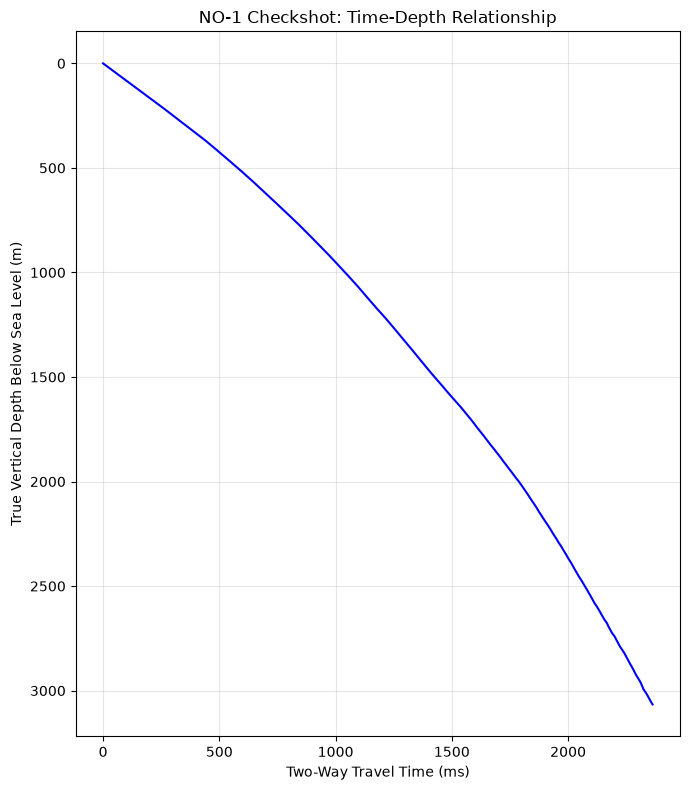


CHECKSHOT VISUALISATION COMPLETED


In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

well = "no-1"

base = Path(
    "/data/epic20/APGCE/input_data/"
    "challenge1_challenge2/well_data"
)

# 1. Read the actual checkshot measurements
checkshot_path = (
    base / "checkshots" /
    f"{well}_Checkshot.txt"
)

cs = np.loadtxt(
    checkshot_path,
    comments="#",
    usecols=(0, 1)
)

tvdss = cs[:, 0]
twt = cs[:, 1]

# 2. Check time-depth quality
print("NO-1 CHECKSHOT ANALYSIS")
print("=" * 50)

print("Checkshot points:", len(tvdss))
print("Minimum depth:", tvdss.min(), "m TVDSS")
print("Maximum depth:", tvdss.max(), "m TVDSS")
print("Maximum TWT:", twt.max(), "ms")

print(
    "Depth increasing:",
    bool(np.all(np.diff(tvdss) > 0))
)

print(
    "Time increasing:",
    bool(np.all(np.diff(twt) > 0))
)

# 3. Inspect well deviation
deviation_path = (
    base / "deviations" /
    f"{well}_Deviation.txt"
)

deviation = np.loadtxt(
    deviation_path,
    comments="#"
)

print("\nWELL TRAJECTORY")
print("=" * 50)

print(
    "Maximum inclination:",
    np.max(np.abs(deviation[:, 2])),
    "degrees"
)

# 4. Plot the actual checkshot relationship
plt.figure(figsize=(7, 8))

plt.plot(
    twt,
    tvdss,
    color="blue",
    linewidth=1.5
)

plt.gca().invert_yaxis()

plt.xlabel("Two-Way Travel Time (ms)")
plt.ylabel("True Vertical Depth Below Sea Level (m)")

plt.title("NO-1 Checkshot: Time-Depth Relationship")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nCHECKSHOT VISUALISATION COMPLETED")
